# Zimbabwe maize yield atlas

The first map follows a maize crop cut from a national view down to the sampling locations in Guruve and Shurugwi. The next maps compare measured and predicted yield, follow vegetation through the growing season and put three years of weather in context. Each map pairs a description with a full-resolution download.

The national overview, linked close-ups and harvest-year panels adapt the layout of Fig. 5 in Jin et al. (2019) to Zimbabwe's crop-cut data. The grayscale landscape comes from the 2016 EOX Sentinel-2 cloudless mosaic. The year labels on the colored layers identify the observations used for yield, vegetation or weather. [Jin et al.](https://doi.org/10.1016/j.rse.2019.04.016) · [EOX imagery](https://maps.eox.at/)

[Zimbabwe maps](#zimbabwe-maps) · [Yield distributions](#yield-distributions-across-harvests) · [Satellite and model figures](#satellite-observations-and-model-estimates) · [Weather associations](#how-regional-weather-and-measured-yield-vary-together) · [Existing figure gallery](#repository-figure-gallery)

**Run the atlas.** Open this notebook in a Git checkout, select the project's Python environment and run the cells in order. The figures below also have saved outputs for reading on GitHub. New PNGs and the source index are in the [atlas output folder](../results/visual_atlas/). [Environment requirements](../requirements.txt).

In [1]:
from pathlib import Path
import sys
from io import BytesIO
from PIL import Image as PILImage

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / "configs" / "team_database_v2.json").is_file())
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
OUT = ROOT / "results" / "visual_atlas"
OUT.mkdir(parents=True, exist_ok=True)
weather_dir = ROOT / "data" / "processed" / "zimbabwe_weather_v2"
fields = pd.read_parquet(weather_dir / "harmonized_labels_weather.parquet")
assert fields.obs_id.is_unique and fields.country_iso3.eq("ZWE").all()
assert np.isfinite(fields.yield_t_ha).all()

def show_file(path):
    display(Image(filename=str(path), width=1000))

def show_map(path, alt):
    # Full-resolution PNGs are linked in the captions. Compact previews travel with the notebook.
    with PILImage.open(path) as source:
        preview = source.convert("RGB")
        preview.thumbnail((1550, 1550), PILImage.Resampling.LANCZOS)
        buffer = BytesIO()
        preview.save(buffer, format="JPEG", quality=88, subsampling=0, optimize=True)
    display(Image(data=buffer.getvalue(), format="jpeg", width=1050, alt=alt))

def export_figure(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    show_file(path)

Matplotlib is building the font cache; this may take a moment.


## Zimbabwe maps

Zimbabwe’s border and the cities of Harare and Bulawayo provide geographic reference. The satellite mosaic supplies the backdrop. The colored layers come from field measurements, held-out predictions, dated vegetation observations or NASA POWER weather cells, as described under each map. [Boundary and city sources](../results/visual_atlas/sources/natural_earth_provenance.json) · [Satellite basemap and reuse terms](../results/visual_atlas/sources/satellite_basemap_provenance.json)

### Measured maize yield from country to field

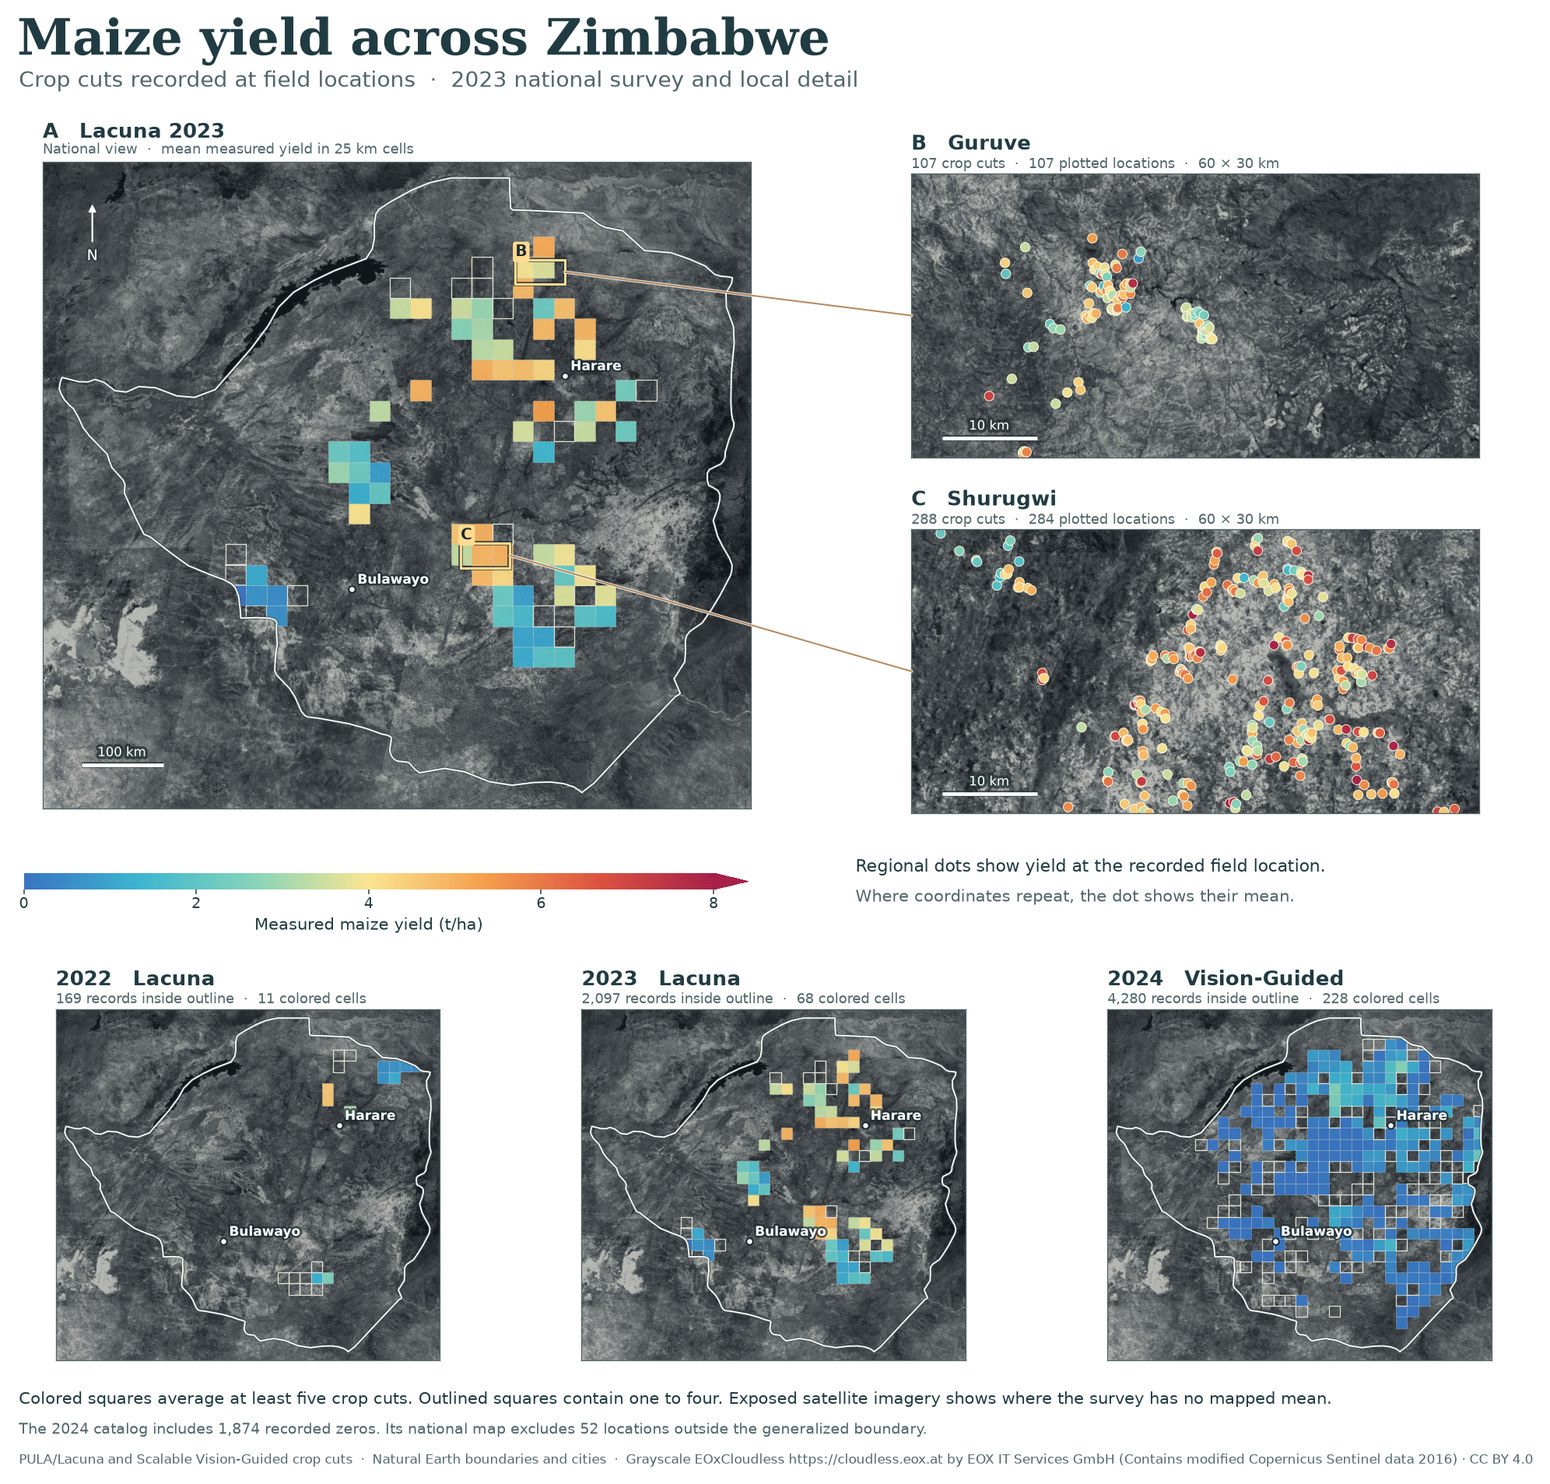

In [2]:
import json
from scripts.paper.atlas_maps import build_maps

map_figures = build_maps(ROOT, OUT)
for figure in map_figures.values():
    plt.close(figure)
map_data = json.loads((OUT / "map_data_summary.json").read_text())
show_map(OUT / "yield_map.png",
         "Measured maize yield on a satellite map of Zimbabwe with Guruve and Shurugwi field close-ups and three harvest-year panels.")

The large 2023 panel shows mean crop-cut yield in tonnes per hectare (t/ha). Blue marks lower yields and red marks higher yields. The upper color includes values of 8 t/ha and above. The boxes locate Guruve and Shurugwi. Their close-ups show measurements at recorded field locations, with coincident measurements averaged for display. Guruve contains 107 records at 107 locations. Shurugwi contains 288 records at 284 locations. The close-ups were selected for the concentration of sampled records within 60 km × 30 km windows on either side of 19° S.

The three smaller maps apply one yield scale across the 2022, 2023 and 2024 harvests. Each colored 25 km square contains at least five field observations. The 2022 sample covers comparatively few places. The 2024 source samples more of the country and includes 1,874 recorded zeros in its screened catalog. Of its 4,332 records, 52 coordinates fall outside the generalized border and are omitted from the map. These are comparisons of sampled fields across different providers and years. [Full-size yield map](../results/visual_atlas/yield_map.png) · [Coverage counts](../results/visual_atlas/map_data_summary.json)

### Measured yield and prediction error

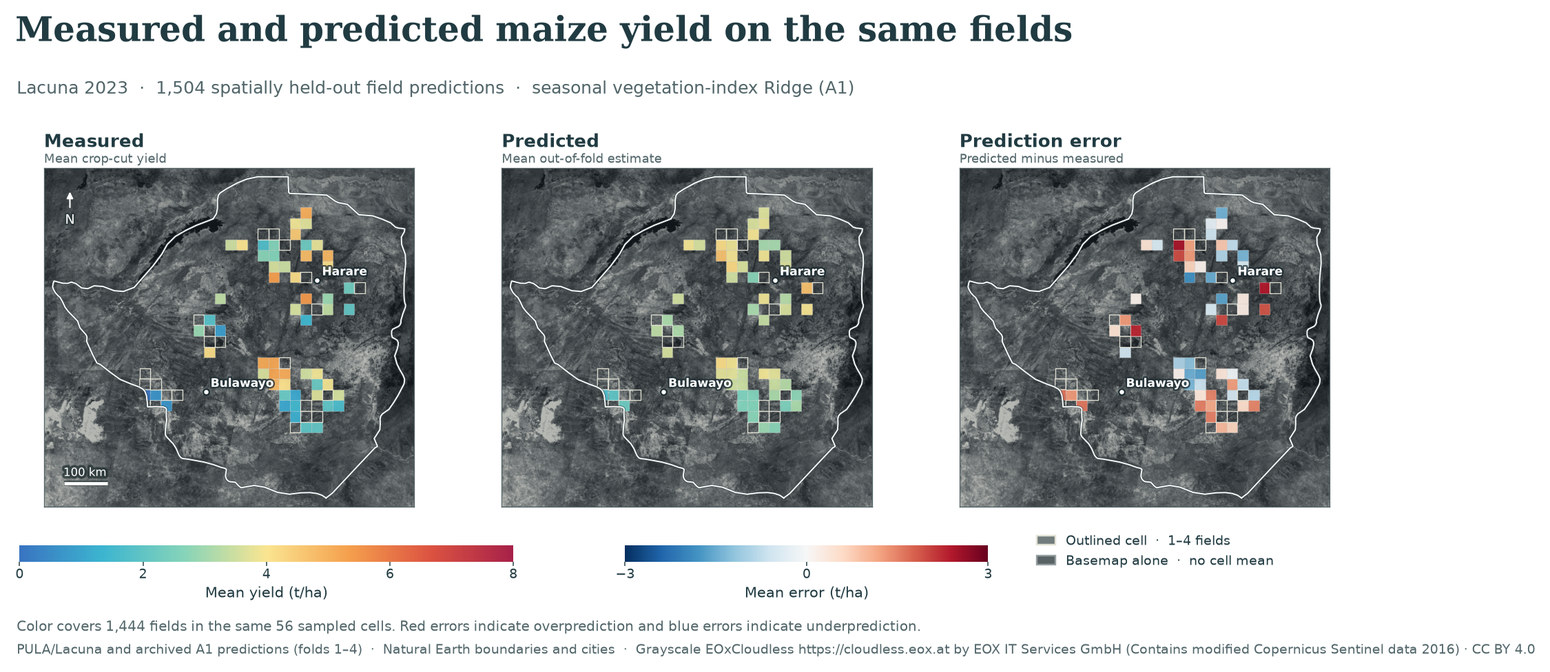

In [3]:
show_map(OUT / "prediction_map.png",
         "Measured yield, held-out Ridge predictions and signed prediction errors for the same Lacuna 2023 field sample.")

The first panel averages measured crop cuts and the second averages satellite-based Ridge estimates over the same fields, in t/ha. The third gives predicted minus measured yield. Red cells mark overestimation and blue cells mark underestimation. The national shape provides context for 1,504 Lacuna fields held out across four spatial development folds. Of these, 1,444 contribute to the 56 cells with at least five fields. Grouping by cell allows opposite errors at individual fields to cancel. [Full-size prediction map](../results/visual_atlas/prediction_map.png) · [Field predictions](../experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/predictions.csv)

### Where the maize canopy was greener

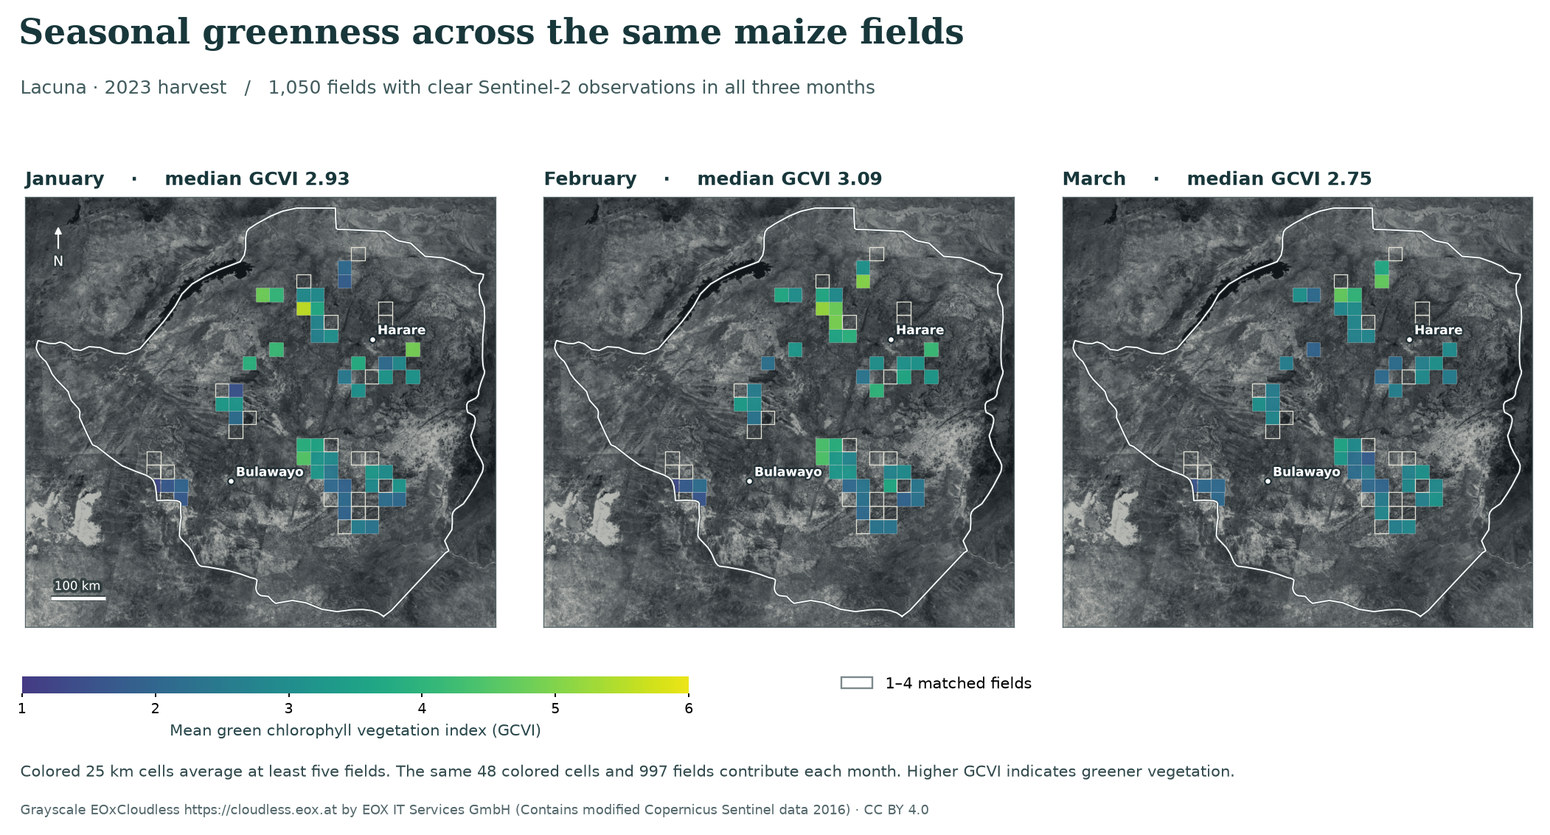

,month,primary_fields,fields_with_all_three_months,inside_outline,colored_cells,fields_in_colored_cells,median_of_cell_means_gcvi
0,2023-01,1880,1050,1050,48,997,2.93
1,2023-02,1880,1050,1050,48,997,3.09
2,2023-03,1880,1050,1050,48,997,2.75


In [4]:
from scripts.paper.atlas_greenness_map import build_greenness_map

gcvi_support = build_greenness_map(ROOT, OUT)
show_map(OUT / "greenness_map.png",
         "January, February and March Sentinel-2 greenness for the same 48 supported Lacuna 2023 grid cells.")
display(gcvi_support.round(2))

Each panel uses the same fields with a clear Sentinel-2 measurement in January, February and March 2023. The green chlorophyll vegetation index (GCVI) compares near-infrared and green reflectance. Purple-blue cells have lower GCVI and yellow-green cells have higher GCVI. The median of the 48 colored cell means rose from 2.93 in January to 3.09 in February, then fell to 2.75 in March. Of the 1,880 primary fields, 1,050 had all three observations and 997 contribute to cells with at least five matched fields. This fixed sample makes month-to-month comparisons easier to interpret. [Full-size greenness map](../results/visual_atlas/greenness_map.png) · [Monthly observations and provenance](../data/processed/zimbabwe_midterm_v2/README.md)

### Rainfall and temperature during the rainy season

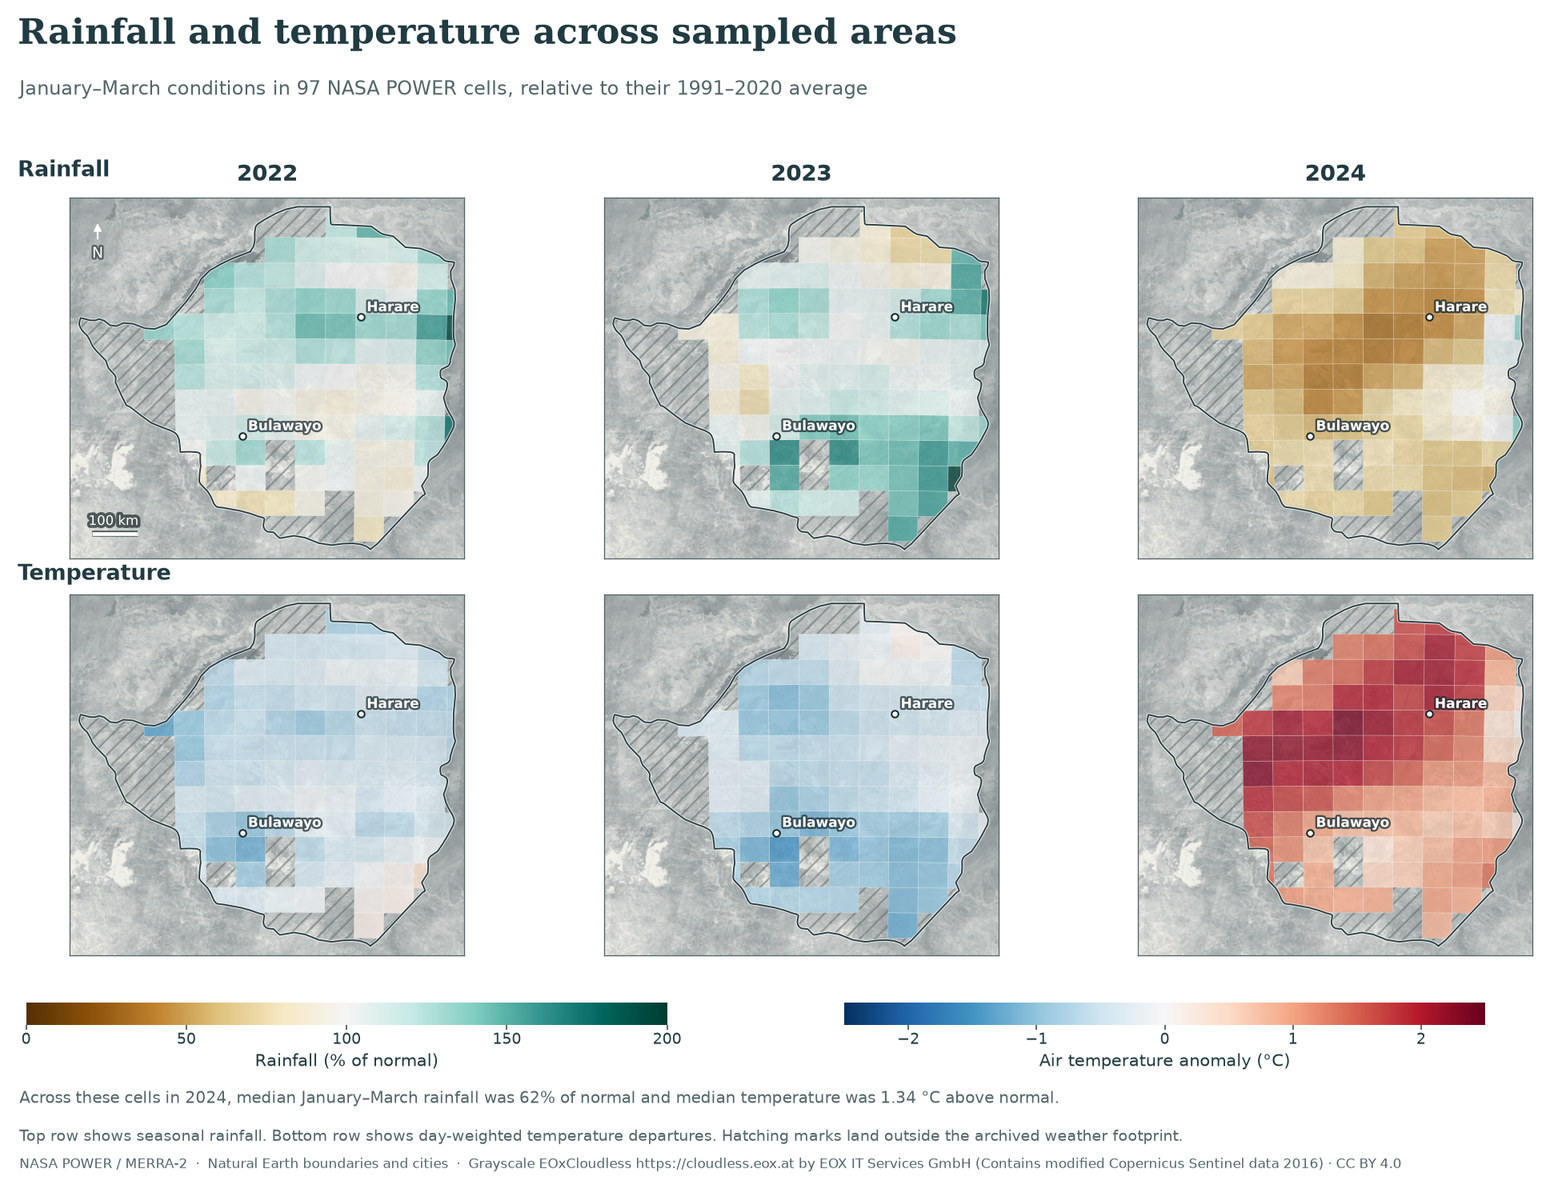

,Median rainfall (% of normal),Median temperature anomaly (°C)
Harvest year,,
2022,113.68,-0.46
2023,110.70,-0.64
2024,62.16,1.34


In [5]:
show_map(OUT / "weather_map.png",
         "January–March rainfall and air-temperature departures for 2022, 2023 and 2024 across the same Zimbabwe weather cells.")
weather_summary = pd.DataFrame({
    int(year): {"Median rainfall (% of normal)": v["rain_pct"]["median"],
                "Median temperature anomaly (°C)": v["temp_anomaly"]["median"]}
    for year, v in map_data["weather"]["years"].items()
}).T.rename_axis("Harvest year")
display(weather_summary.round(2))

Each column is a harvest year. The rainfall row gives the January–March total as a percentage of the 1991–2020 normal in each POWER cell. Brown cells received less rainfall than usual and teal cells received more. The temperature row gives the departure from the normal in °C, with blue for cooler and red for warmer conditions. Across the same 97 archived cells, median rainfall was 114% of normal in 2022, 111% in 2023 and 62% in 2024. Median temperature departures were −0.46, −0.64 and +1.34 °C, respectively. This comparison describes regional conditions over the sampled footprint. The backdrop is the same reference satellite mosaic in each panel. [Full-size weather map](../results/visual_atlas/weather_map.png) · [Weather data](../data/processed/zimbabwe_weather_v2/README.md)

## Yield distributions across harvests

Following the distribution comparison in Jin et al. Fig. 6a, each curve shows the fraction of recorded fields with yield at or below a given value. Every field contributes one observation. The solid lines use the screened catalog. Dashed lines apply the project's v2 primary-label rule before satellite coverage and spatial splits. The 2024 sensitivity is particularly important because 1,874 of its 4,332 records report zero. Their measurement status is uncertain and v2 excludes them from training. The 2022 panel contains ground observations only. [Input records](../data/processed/zimbabwe_weather_v2/harmonized_labels_weather.parquet).

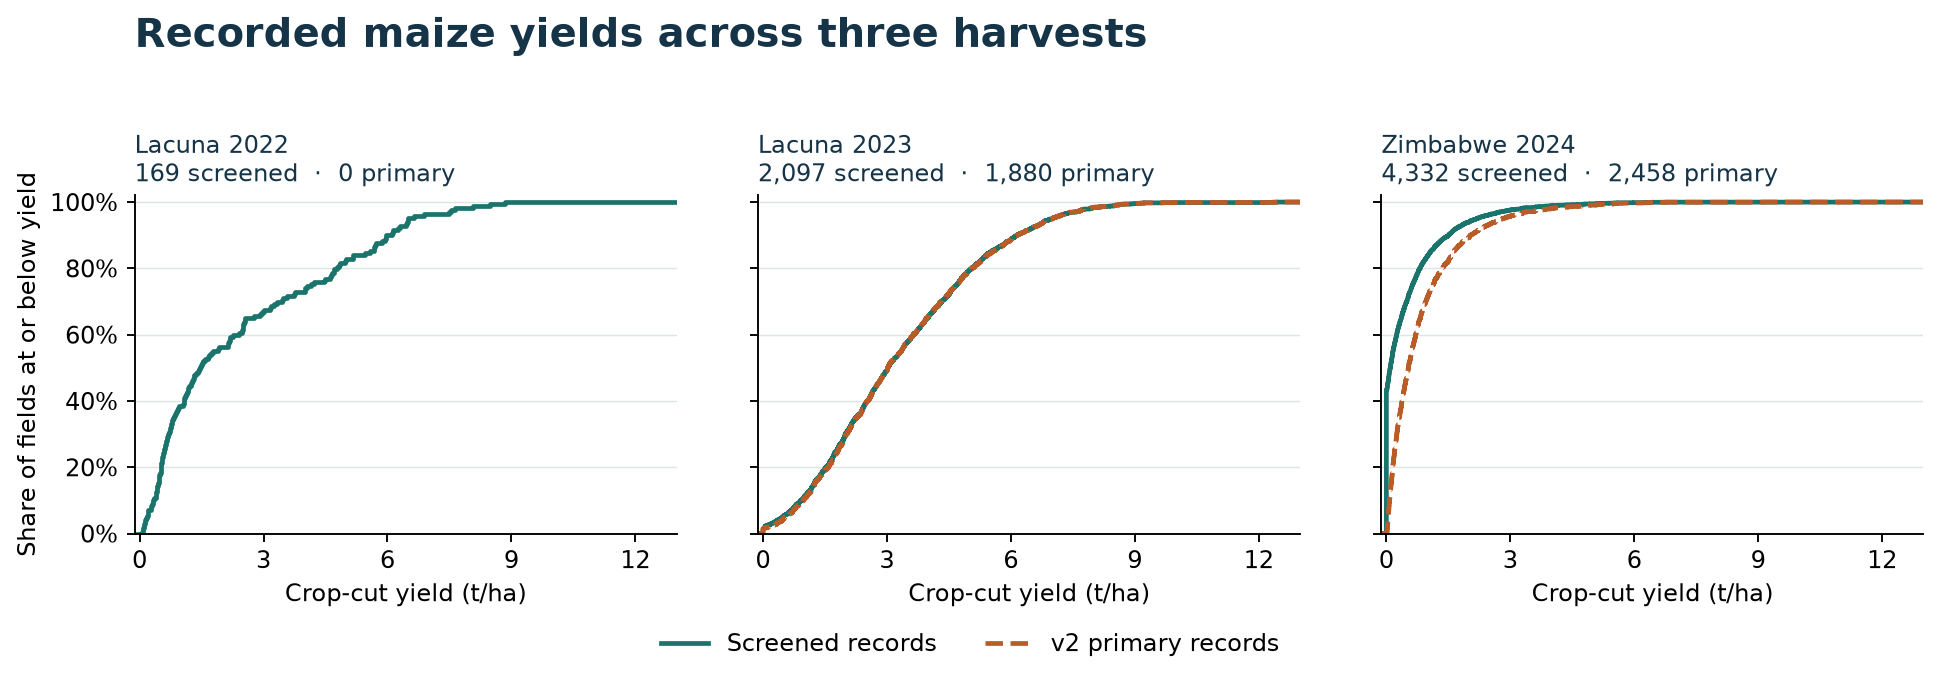

,fields,q05,median,q95
season_year,,,,
2022,169,0.18,1.46,6.50
2023,2097,0.48,3.02,7.00
2024,4332,0.00,0.09,2.18


In [6]:
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

season_names = {2022: "Lacuna 2022", 2023: "Lacuna 2023", 2024: "Zimbabwe 2024"}
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9), sharex=True, sharey=True)
fig.subplots_adjust(left=.07, right=.985, top=.72, bottom=.21, wspace=.15)
fig.suptitle("Recorded maize yields across three harvests", x=.07, y=.99, ha="left",
             fontsize=17, fontweight="bold", color="#163447")
for ax, (year, label) in zip(axes, season_names.items()):
    sample = fields.loc[fields.season_year.eq(year)]
    for pool, color, style in [(sample, "#1A746B", "-"),
                               (sample.loc[sample.include_primary], "#B95C28", "--")]:
        if pool.empty:
            continue
        y, counts = np.unique(pool.yield_t_ha, return_counts=True)
        ax.step(np.r_[-.12, y, 13], np.r_[0, counts.cumsum()/counts.sum(), 1],
                where="post", color=color, linestyle=style, linewidth=2)
    ax.set_title(f"{label}\n{len(sample):,} screened  ·  {sample.include_primary.sum():,} primary",
                 loc="left", fontsize=10, color="#163447")
    ax.grid(axis="y", color="#DDE5E6", linewidth=.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set(xlim=(-.12, 13), ylim=(0, 1.02), xticks=[0, 3, 6, 9, 12], xlabel="Crop-cut yield (t/ha)")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Share of fields at or below yield")
fig.legend([Line2D([], [], color="#1A746B", lw=2), Line2D([], [], color="#B95C28", ls="--", lw=2)],
           ["Screened records", "v2 primary records"], loc="lower center", ncol=2, frameon=False)
export_figure(fig, "yield_distributions.png")

summary = fields.groupby("season_year").yield_t_ha.agg(
    fields="size", q05=lambda s: s.quantile(.05), median="median", q95=lambda s: s.quantile(.95))
display(summary.round(2))

The median recorded yield was 3.02 t/ha for Lacuna 2023 and 0.09 t/ha for the screened 2024 source. The two providers sampled different fields and used different crop-cut protocols. The solid and dashed curves show how sample selection changes the 2024 comparison.

## Satellite observations and model estimates

### Seasonal greenness

Jin et al. used the seasonal course of GCVI, the green chlorophyll vegetation index, in their yield analysis (§4.1.2). We group 1,880 Lacuna 2023 fields by measured harvest yield and show the observed monthly median and interquartile range of GCVI in each group. The count below each month is the number of fields with a usable observation. October and November are gaps. These curves use the original imagery preserved in the corrected v2 handoff table. [Monthly imagery and provenance](../data/processed/zimbabwe_midterm_v2/README.md).

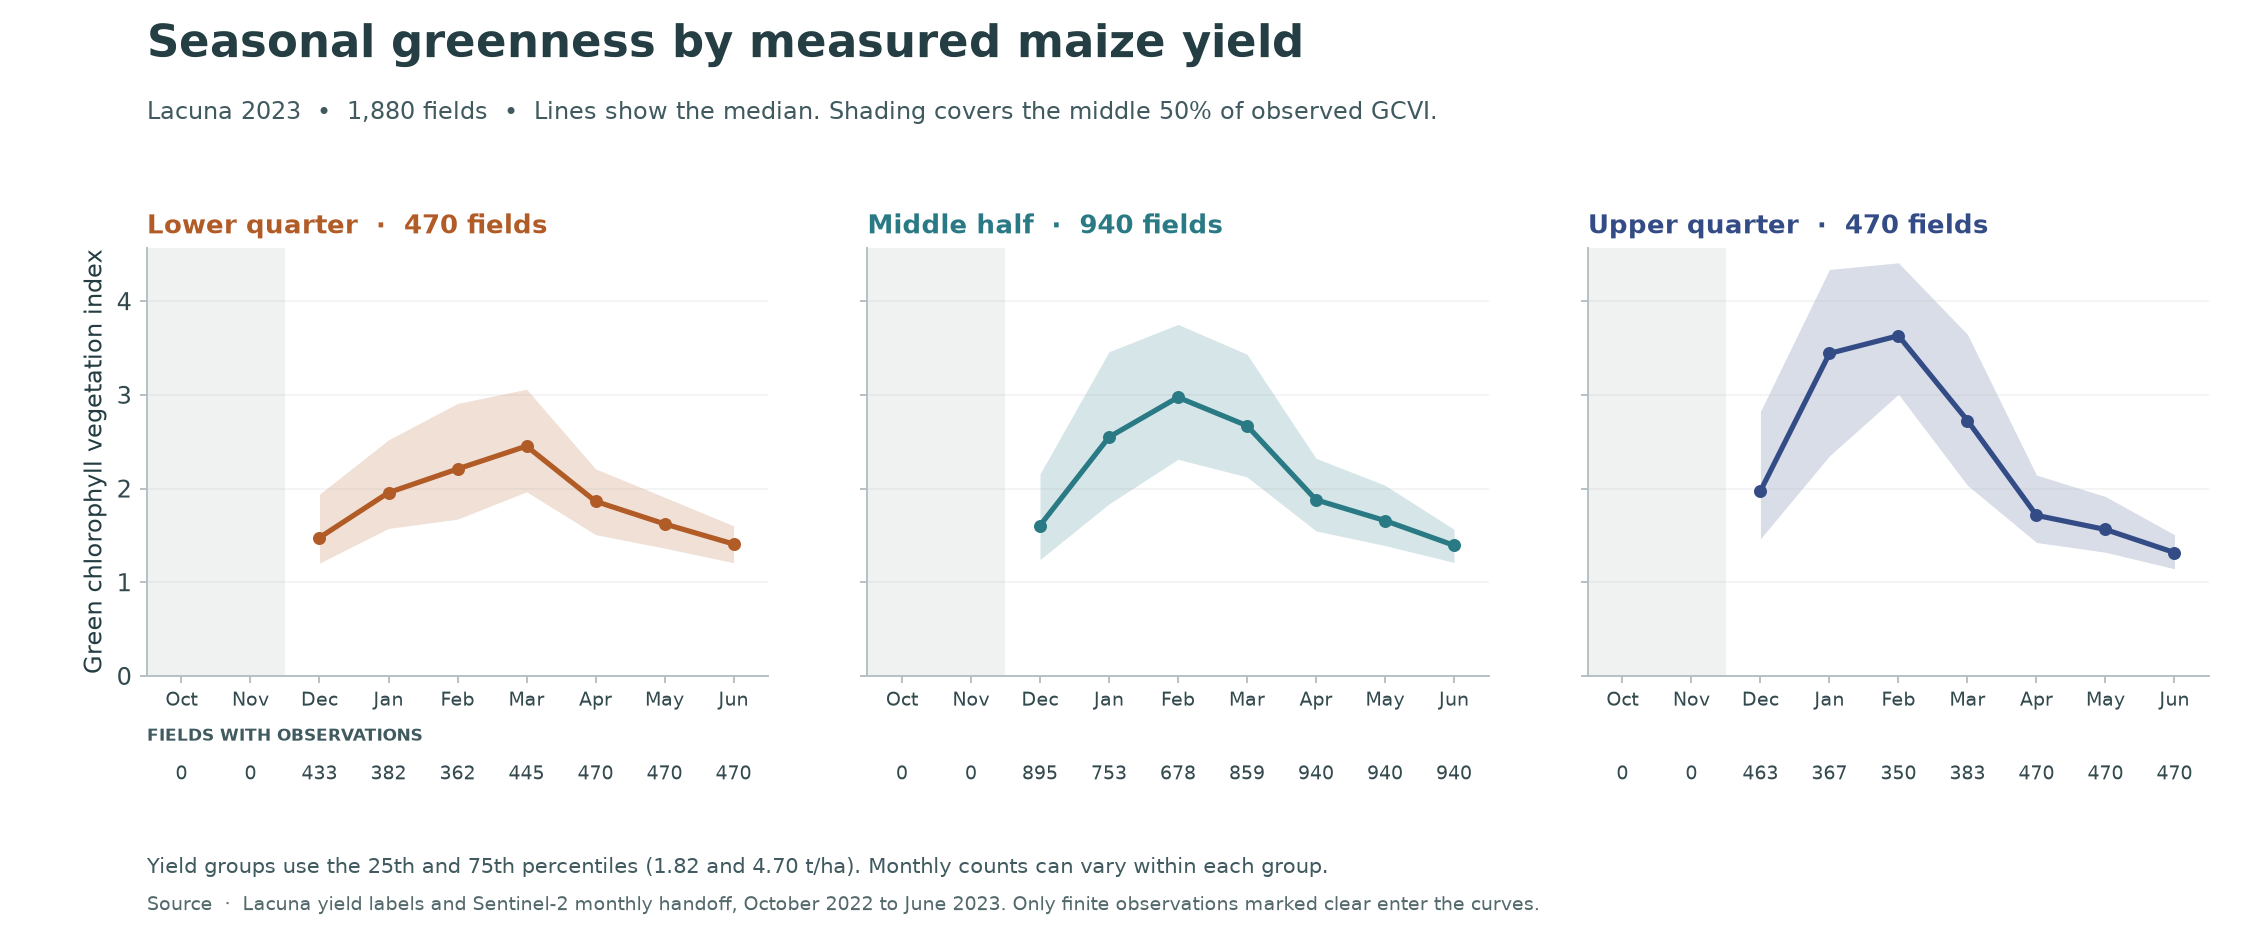

In [7]:
from scripts.paper.atlas_diagnostics import build_diagnostics

diagnostics = build_diagnostics(ROOT, OUT)
show_file(diagnostics["seasonal_gcvi"])

### Agreement with crop cuts at two scales

Jin et al. Fig. 4 compares crop cuts and satellite estimates at district scale. The top row here shows individual Zimbabwe fields. The bottom row averages those same observations within each of the 19 provider administrative units, with equal weight per unit for the area scores. Each dot uses predictions from the **data v2 Presto experiment** on 1,504 development fields. A1 uses seasonal vegetation indices. P0 fits Ridge to frozen Presto embeddings generated by that experiment. These runs allowed fold 0 to supply training fields and scored folds 1–4. The reported R² uses the pooled sum of squared prediction errors at each scale. [Experiment protocol](../experiments/presto_finetune/PLAN.md) · [Saved scores](../experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/scores.csv).

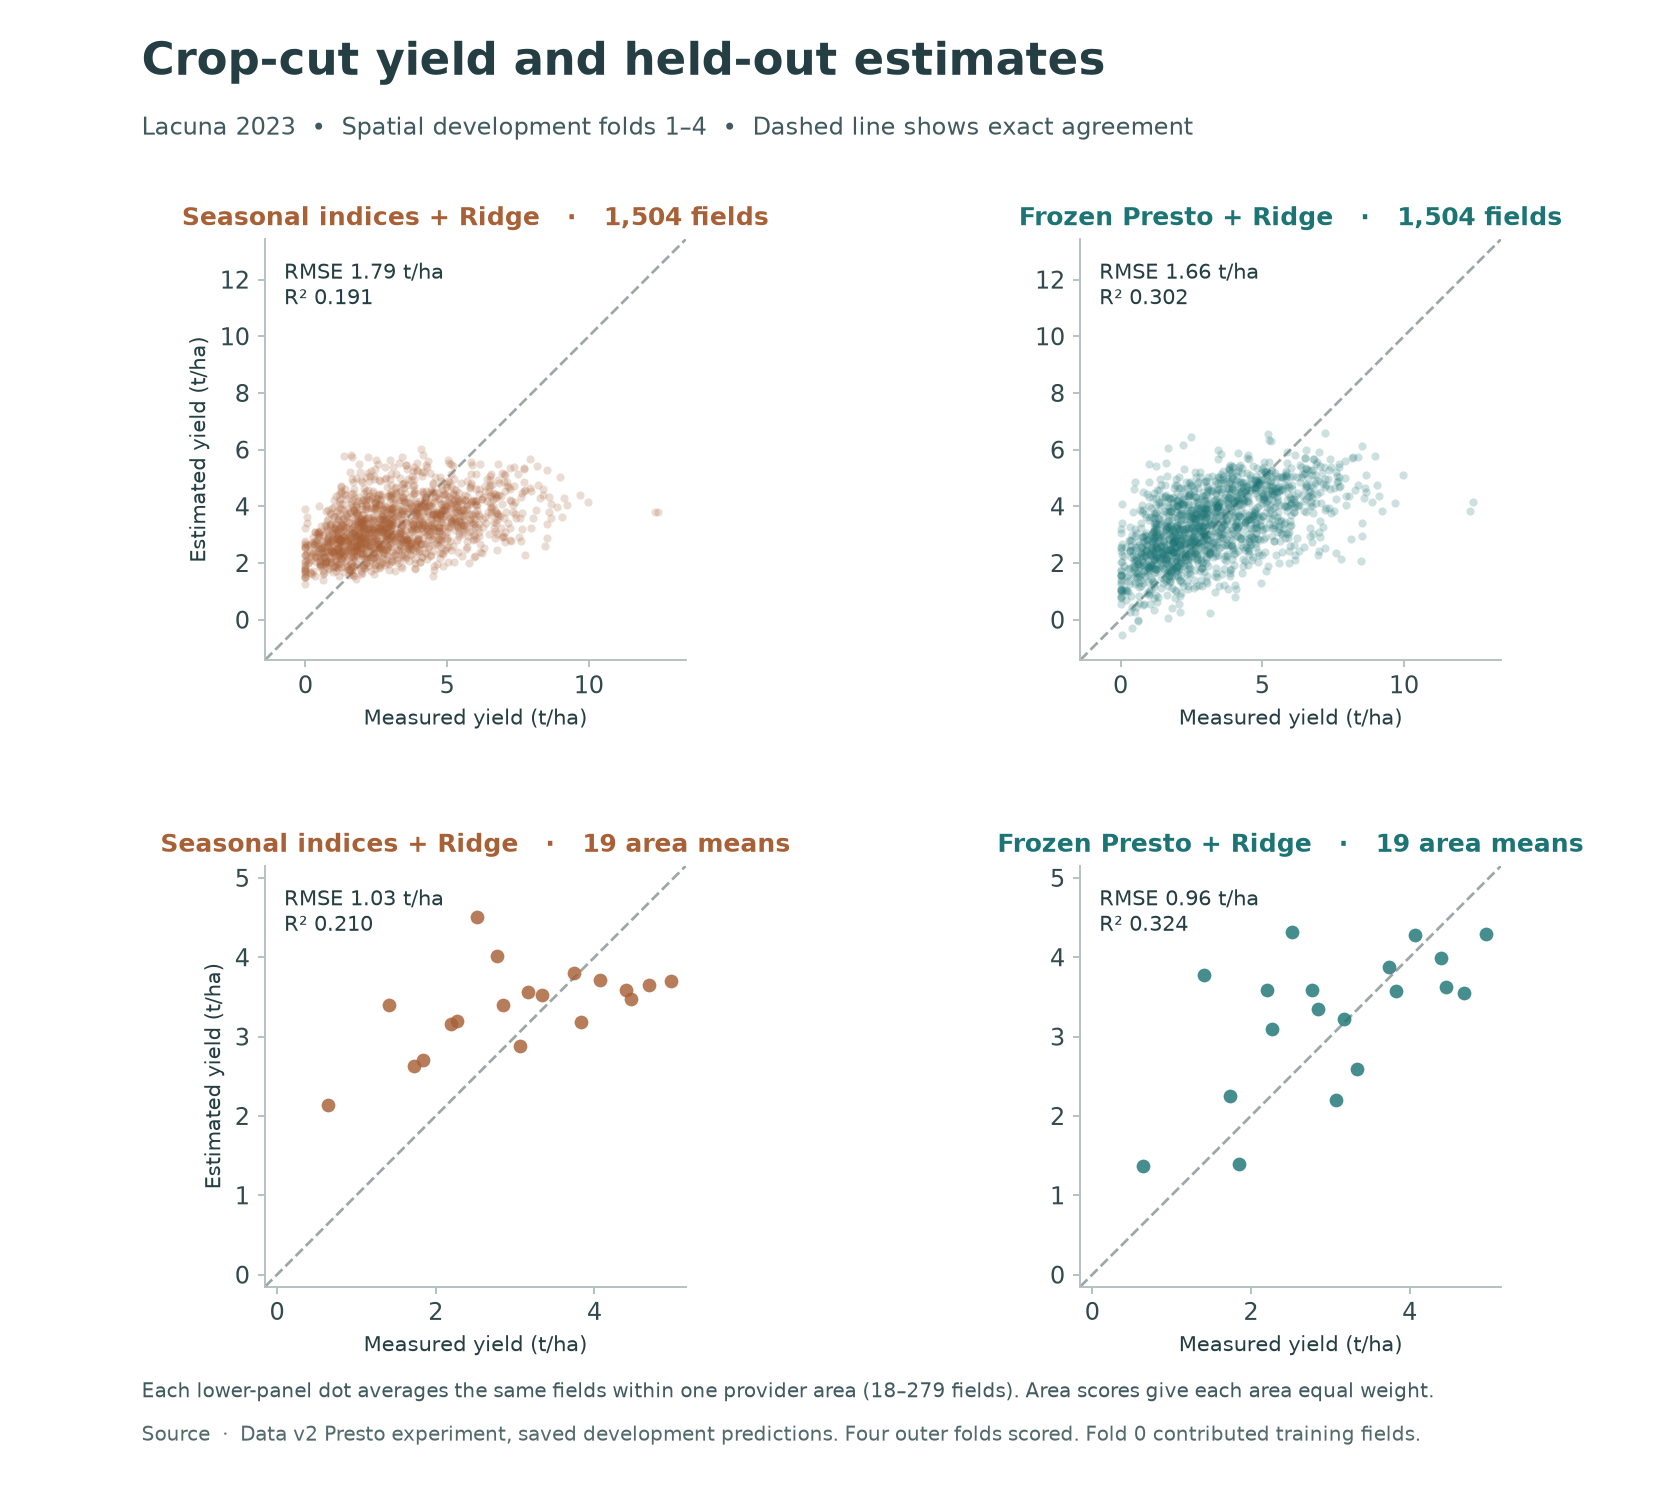

In [8]:
show_file(diagnostics["yield_agreement"])

## How regional weather and measured yield vary together

Jin et al. Fig. 7a compared yield and soil variables. Here the environmental variables are the four seasonal rainfall and temperature features available in Zimbabwe. A square gives the Pearson correlation across sampled NASA POWER cells within a single harvest and provider. We average v2 primary crop-cut yields first, require at least five primary fields per cell, and give each retained cell equal weight. This keeps multiple fields that share a weather estimate from appearing as separate weather observations. The threshold is a display choice. Spatial dependence and differences in the sampled farms affect these descriptive associations. [NASA source and processing](../docs/zimbabwe/METHODS.md#weather-extraction-and-features).

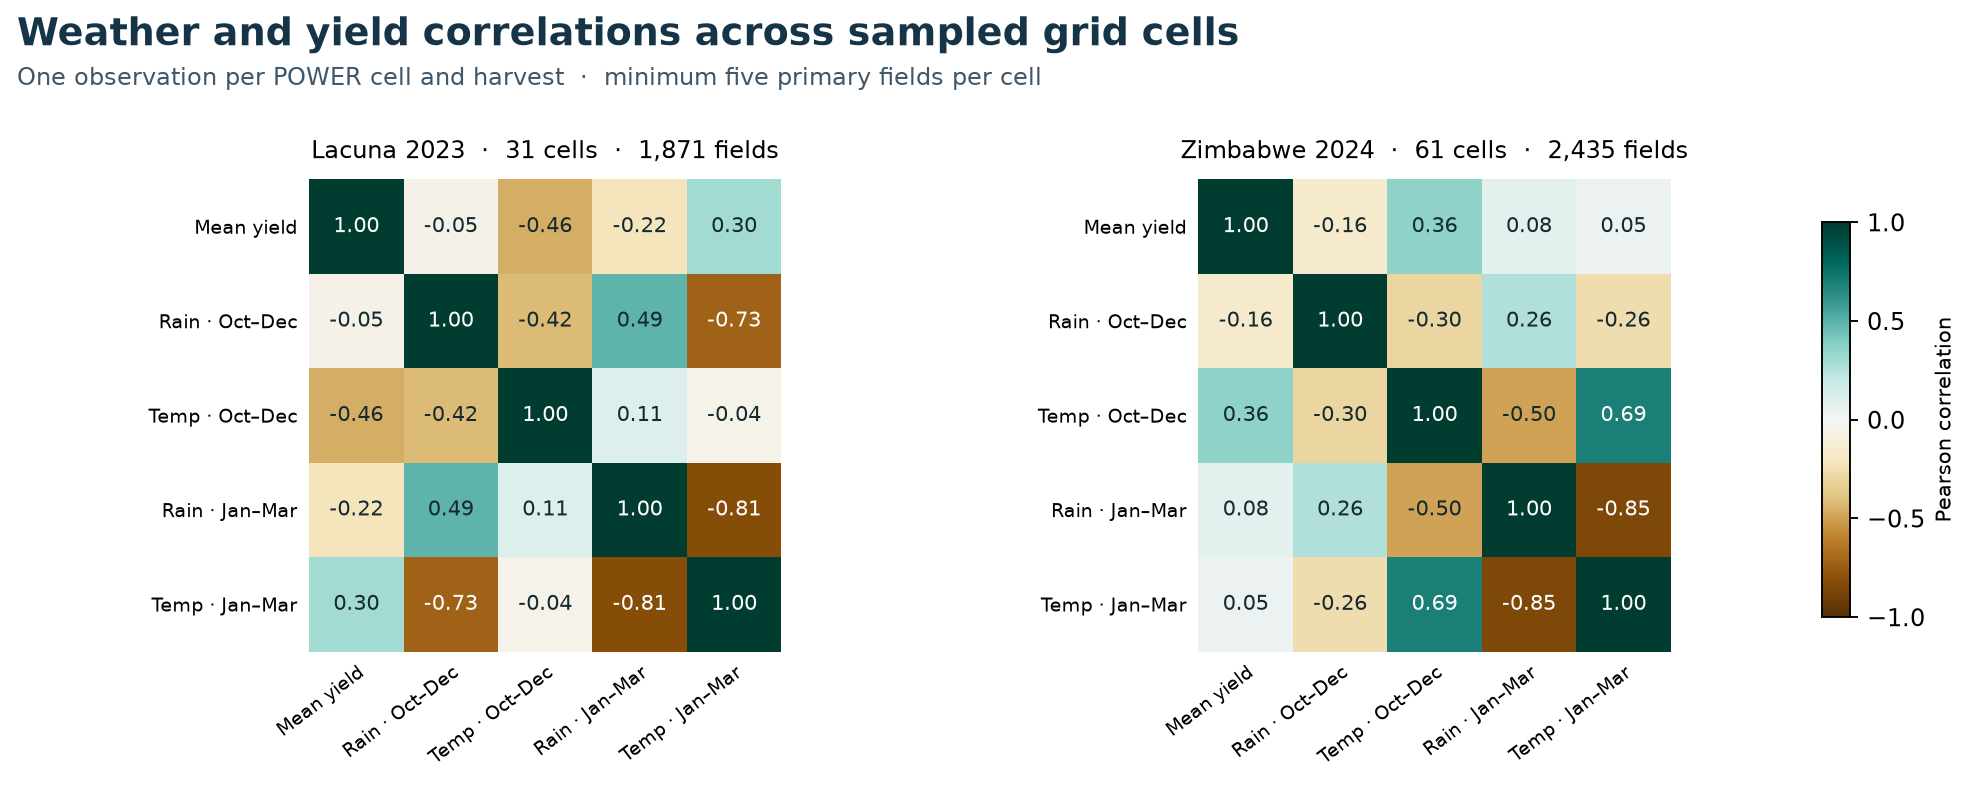

In [9]:
from cropyield.experiments.zimbabwe_weather_compact import early_weather

keys = ["weather_grid_id", "season_year"]
# Use the same October–December calculation as the project's compact-weather experiments.
early = early_weather(pd.read_parquet(weather_dir / "weather_cell_months.parquet"))
weather_cols = {
    "wx_rain_percent_normal_oct_dec": "Rain · Oct–Dec",
    "wx_t2m_anomaly_c_oct_dec": "Temp · Oct–Dec",
    "wx_rain_percent_normal_jan_mar": "Rain · Jan–Mar",
    "wx_t2m_anomaly_c_jan_mar": "Temp · Jan–Mar",
}
primary = fields.loc[fields.include_primary].merge(early, on=keys, validate="many_to_one")
by_cell = primary.groupby(keys)
assert by_cell[list(weather_cols)].nunique(dropna=False).eq(1).all().all()
sampled_cells = by_cell.size().rename("fields").to_frame().join(
    by_cell.yield_t_ha.mean().rename("Mean yield")).join(by_cell[list(weather_cols)].first())
sampled_cells = sampled_cells.loc[sampled_cells.fields.ge(5)].rename(columns=weather_cols).reset_index()
sampled_cells.to_csv(OUT / "weather_yield_cell_means.csv", index=False)

cols = ["Mean yield", *weather_cols.values()]
fig, axes = plt.subplots(1, 2, figsize=(11.8, 5.05))
fig.subplots_adjust(left=.13, right=.89, top=.79, bottom=.24, wspace=.40)
fig.suptitle("Weather and yield correlations across sampled grid cells", x=.025, y=.98,
             ha="left", fontsize=16, fontweight="bold", color="#163447")
fig.text(.025, .90, "One observation per POWER cell and harvest  ·  minimum five primary fields per cell",
         fontsize=10, color="#40576A")
for ax, (year, group) in zip(axes, sampled_cells.groupby("season_year", sort=True)):
    corr = group[cols].corr()
    im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
    ax.set(xticks=range(len(cols)), yticks=range(len(cols)), yticklabels=cols)
    ax.set_xticklabels(cols, rotation=37, ha="right", rotation_mode="anchor")
    ax.tick_params(labelsize=8, length=0, pad=5)
    ax.set_title(f"{season_names[year]}  ·  {len(group)} cells  ·  {group.fields.sum():,} fields",
                 fontsize=10, pad=9)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = corr.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if abs(v) >= .60 else "#142A2E", fontsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
bar = fig.colorbar(im, cax=fig.add_axes([.925, .28, .014, .46]), ticks=[-1, -.5, 0, .5, 1])
bar.set_label("Pearson correlation", fontsize=9)
export_figure(fig, "weather_yield_correlations.png")

Here *rain* is percent of the 1991–2020 normal and *temperature* is departure from the normal in °C. October–December belongs to the calendar year before the harvest. Each coefficient describes variation across the sampled cells within one season. Weather, field management and sampling locations can all vary together. [Cell-level data behind the figure](../results/visual_atlas/weather_yield_cell_means.csv).

## Repository figure gallery

The gallery inventories the tracked project at the start of this atlas, revision [8de629a](https://github.com/FelixYu120/DSC-291-Final-Project/tree/8de629a). It covers standalone images, images embedded in active and archived notebooks, project diagrams, and provider illustrations. Source files that contain identical images share a gallery ID. The gallery also reconstructs report and Presto figures where the plotting code and numeric data were saved separately.

Use the contact sheets to browse. The links below them give the original file and, for notebook figures, the cell and output number. The CSV indexes every source occurrence. For a full-size view in Jupyter set the figure ID in the last cell. Rebuilding this section uses local Git history including revision 8de629a. [Full source index](../results/visual_atlas/figure_inventory.csv).

Geographic and spatial figures carry descriptions below their previews and in the source inventory. The provider’s countrywide modeled-yield illustration is G079 in the provider documentation group.

In [10]:
from scripts.paper.visualization_gallery import GROUPS, collect_gallery, show_gallery, show_figure

gallery = collect_gallery(ROOT)
gallery.write_manifest(OUT / "figure_inventory.csv")
print(f"{len(gallery.items)} unique figures · {len(gallery.rows)} source occurrences")
display(pd.Series(gallery.counts(), name="Unique figure previews").to_frame())

106 unique figures · 118 source occurrences


,Unique figure previews
Standalone project figures,16
Archived notebook figures,26
Notebook figures,27
Archived project diagrams,3
Provider documentation figures,12
Reconstructed v2 report figures,4
Reconstructed Presto diagnostics,18


### Standalone project figures

16 unique previews · 16 figures referenced in this section.

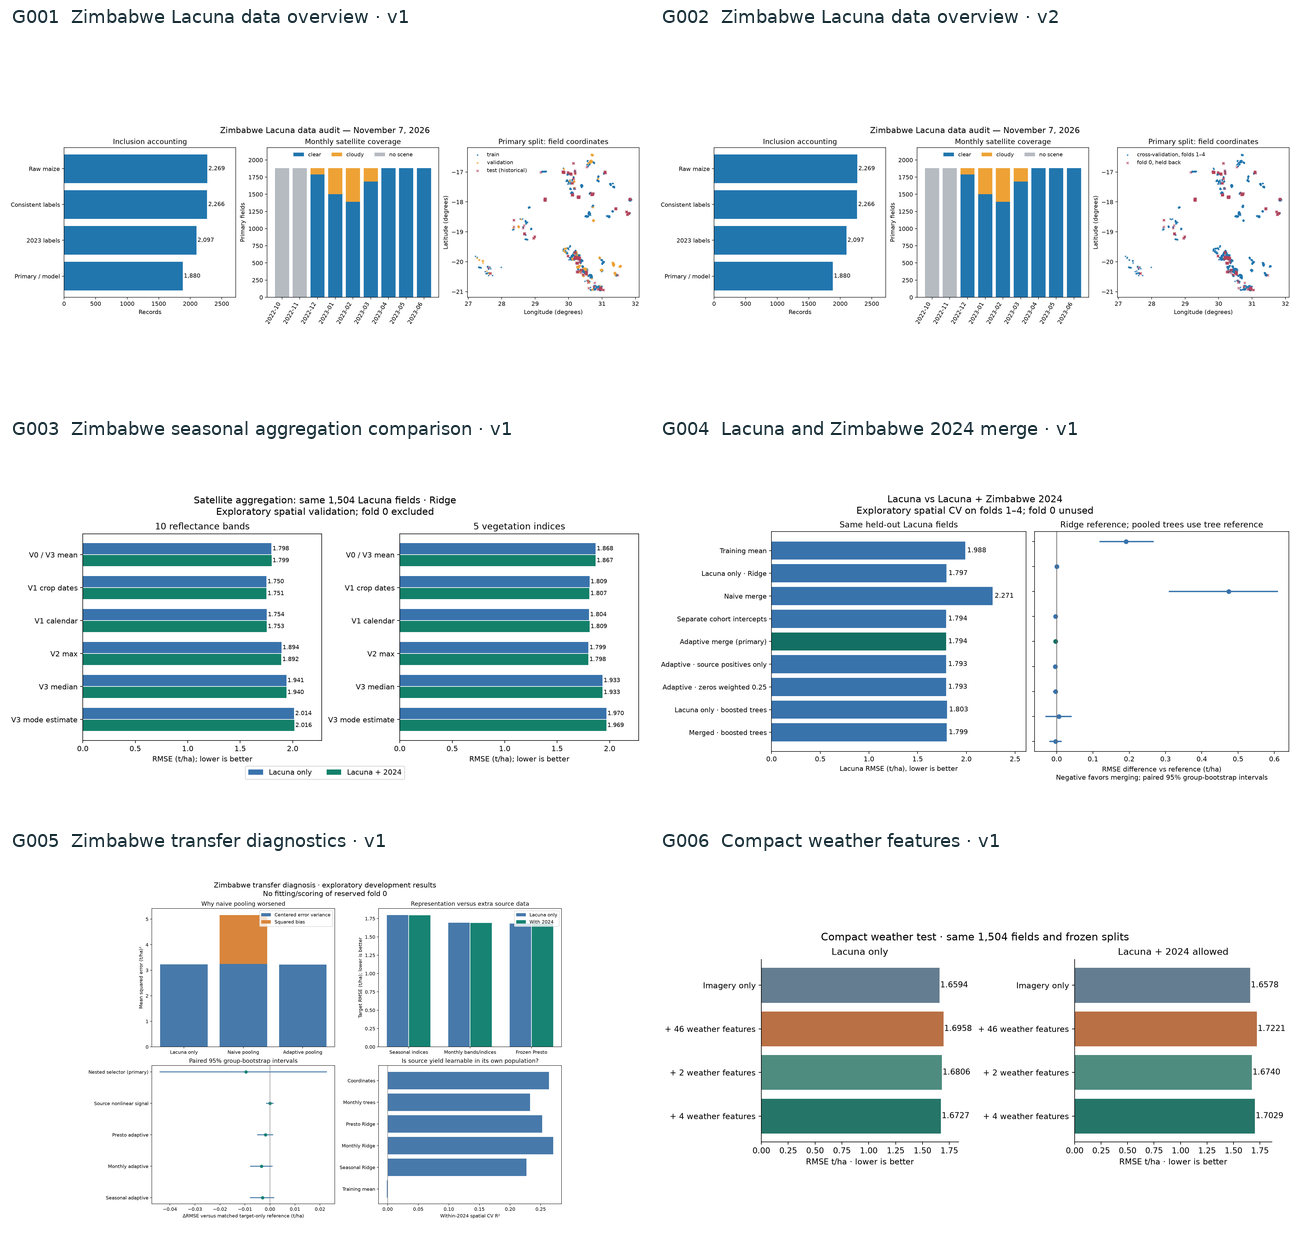

- **G001** The right panel locates the 1,880 primary Lacuna 2023 fields. Blue, orange and red mark the v1 training, validation and historical test labels. The other panels account for exclusions and monthly satellite coverage. [data_overview.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/processed/zimbabwe_midterm_v1/data_overview.png)

- **G002** The right panel locates the same 1,880 primary Lacuna 2023 fields under the v2 split labels. Blue denotes development folds 1–4 and red denotes the held-back fold 0. The left panels show which records and months are available. [data_overview.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/processed/zimbabwe_midterm_v2/data_overview.png)

- **G003** [comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_aggregation_v1/comparison.png)

- **G004** [comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_merge_v1/comparison.png)

- **G005** [diagnosis.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_transfer_diagnosis_v1/diagnosis.png)

- **G006** [compact_weather_comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_weather_compact_v1/compact_weather_comparison.png) · [data_guide_2_zimbabwe.ipynb · cell 41, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)

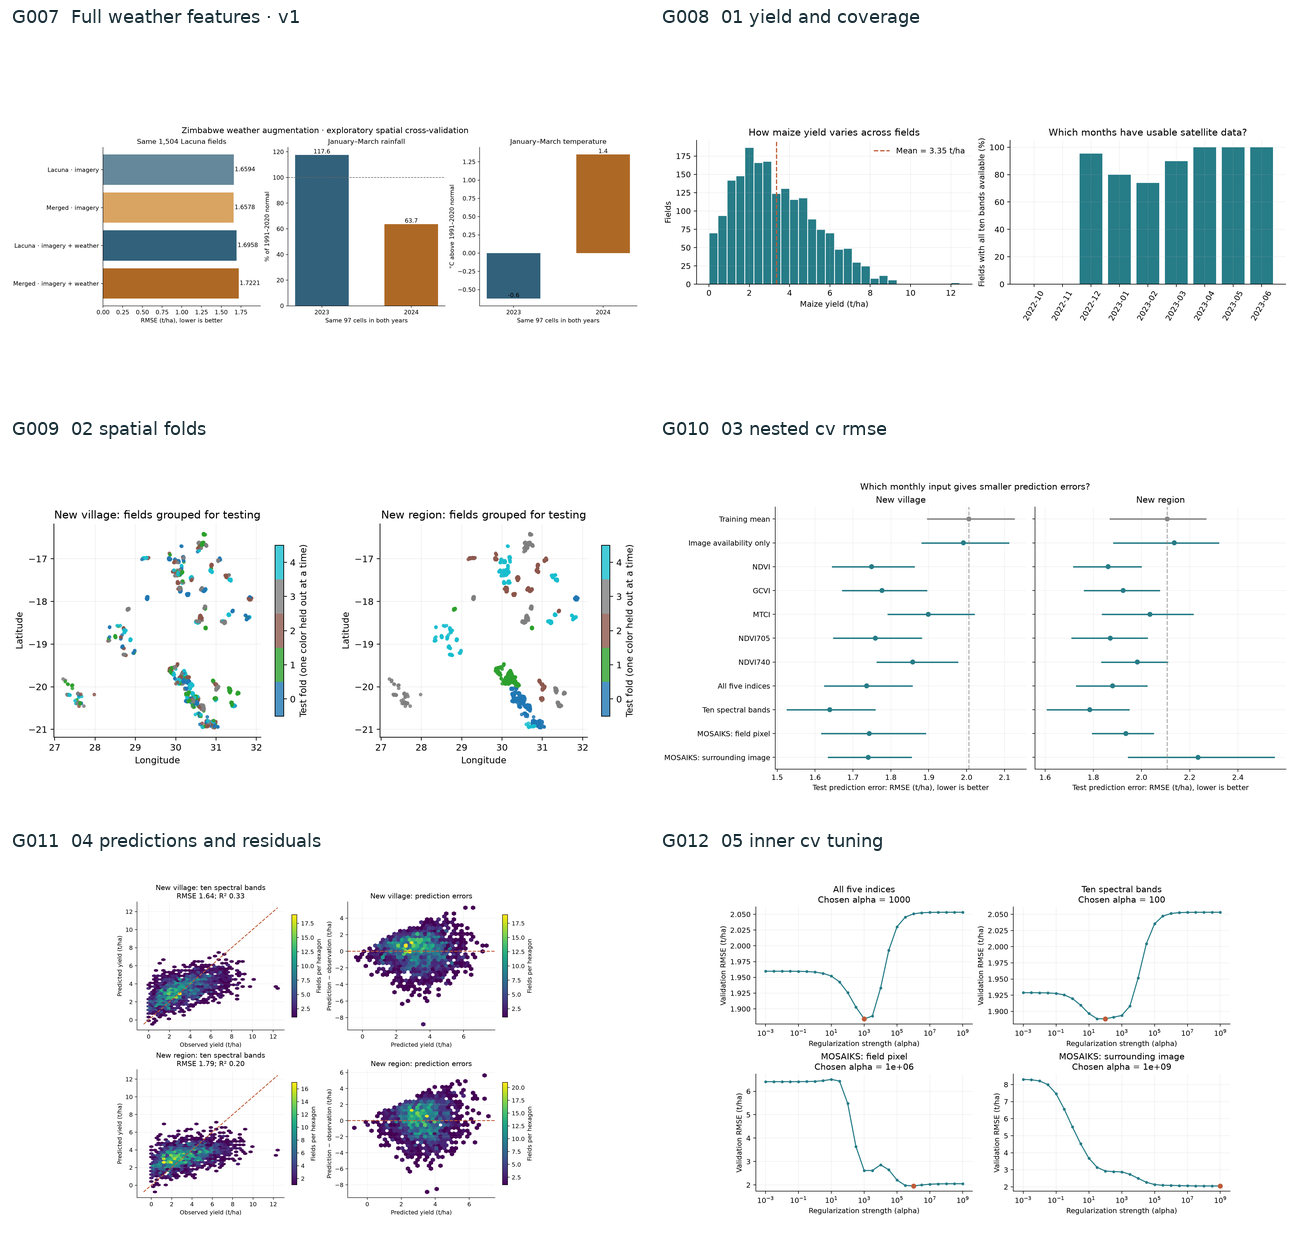

- **G007** [weather_comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_weather_v1/weather_comparison.png)

- **G008** [01_yield_and_coverage.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/01_yield_and_coverage.png)

- **G009** Each dot locates a Lacuna 2023 field. Colors identify the five test folds. The left panel assigns nearby villages to folds, while the right panel holds together fields in the same provider region. [02_spatial_folds.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/02_spatial_folds.png)

- **G010** [03_nested_cv_rmse.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/03_nested_cv_rmse.png)

- **G011** [04_predictions_and_residuals.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/04_predictions_and_residuals.png)

- **G012** [05_inner_cv_tuning.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/05_inner_cv_tuning.png)

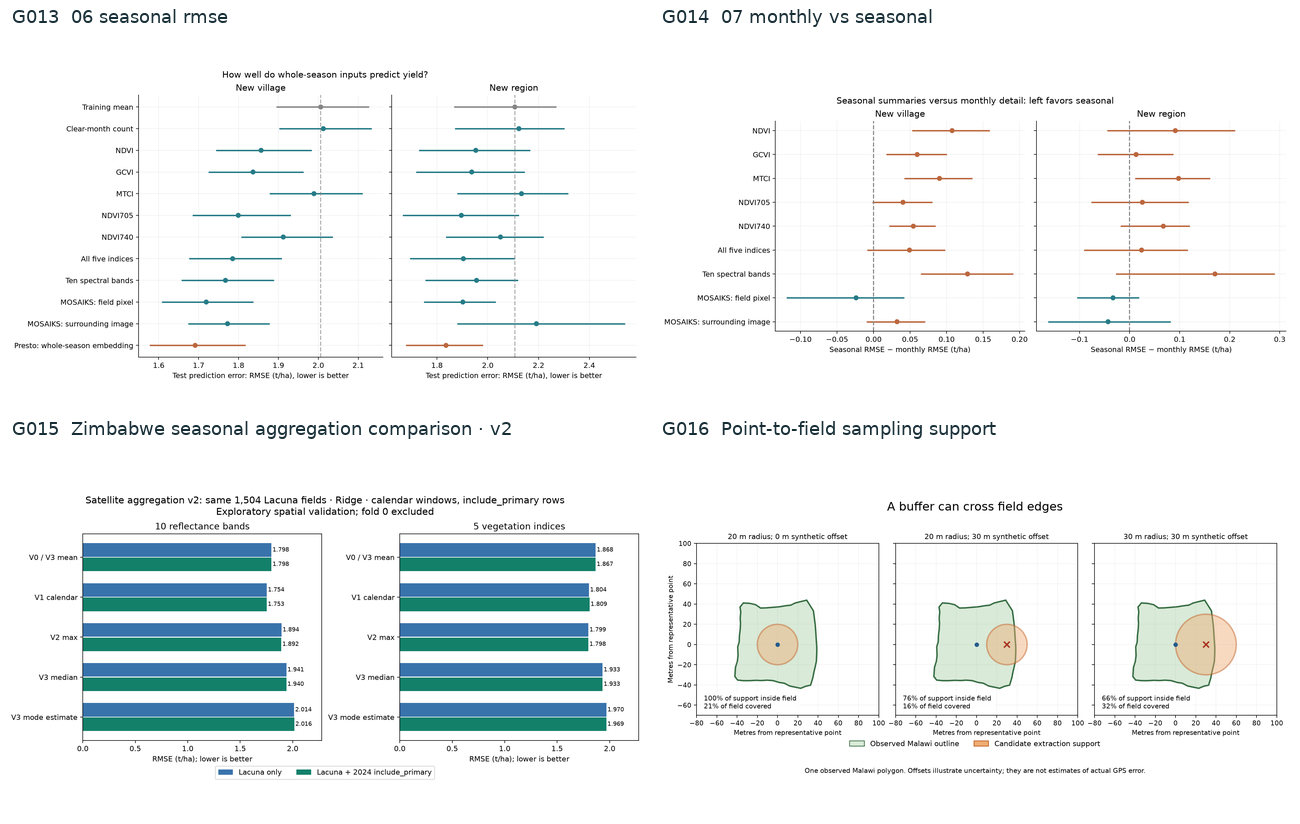

- **G013** [06_seasonal_rmse.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/06_seasonal_rmse.png)

- **G014** [07_monthly_vs_seasonal.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/07_monthly_vs_seasonal.png)

- **G015** [comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/aggregation_v2/comparison.png)

- **G016** The green boundary is a surveyed Malawi field. Each orange circle is a proposed sampling area. Increasing its radius or shifting its center 30 m moves part of the circle across the surveyed boundary. [point_area_example.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/quality_remediation/point_area_example.png) · [data_quality_review.ipynb · cell 30, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

In [11]:
show_gallery(gallery, "Standalone project figures")

### Notebook figures

27 unique previews · 29 figures referenced in this section.

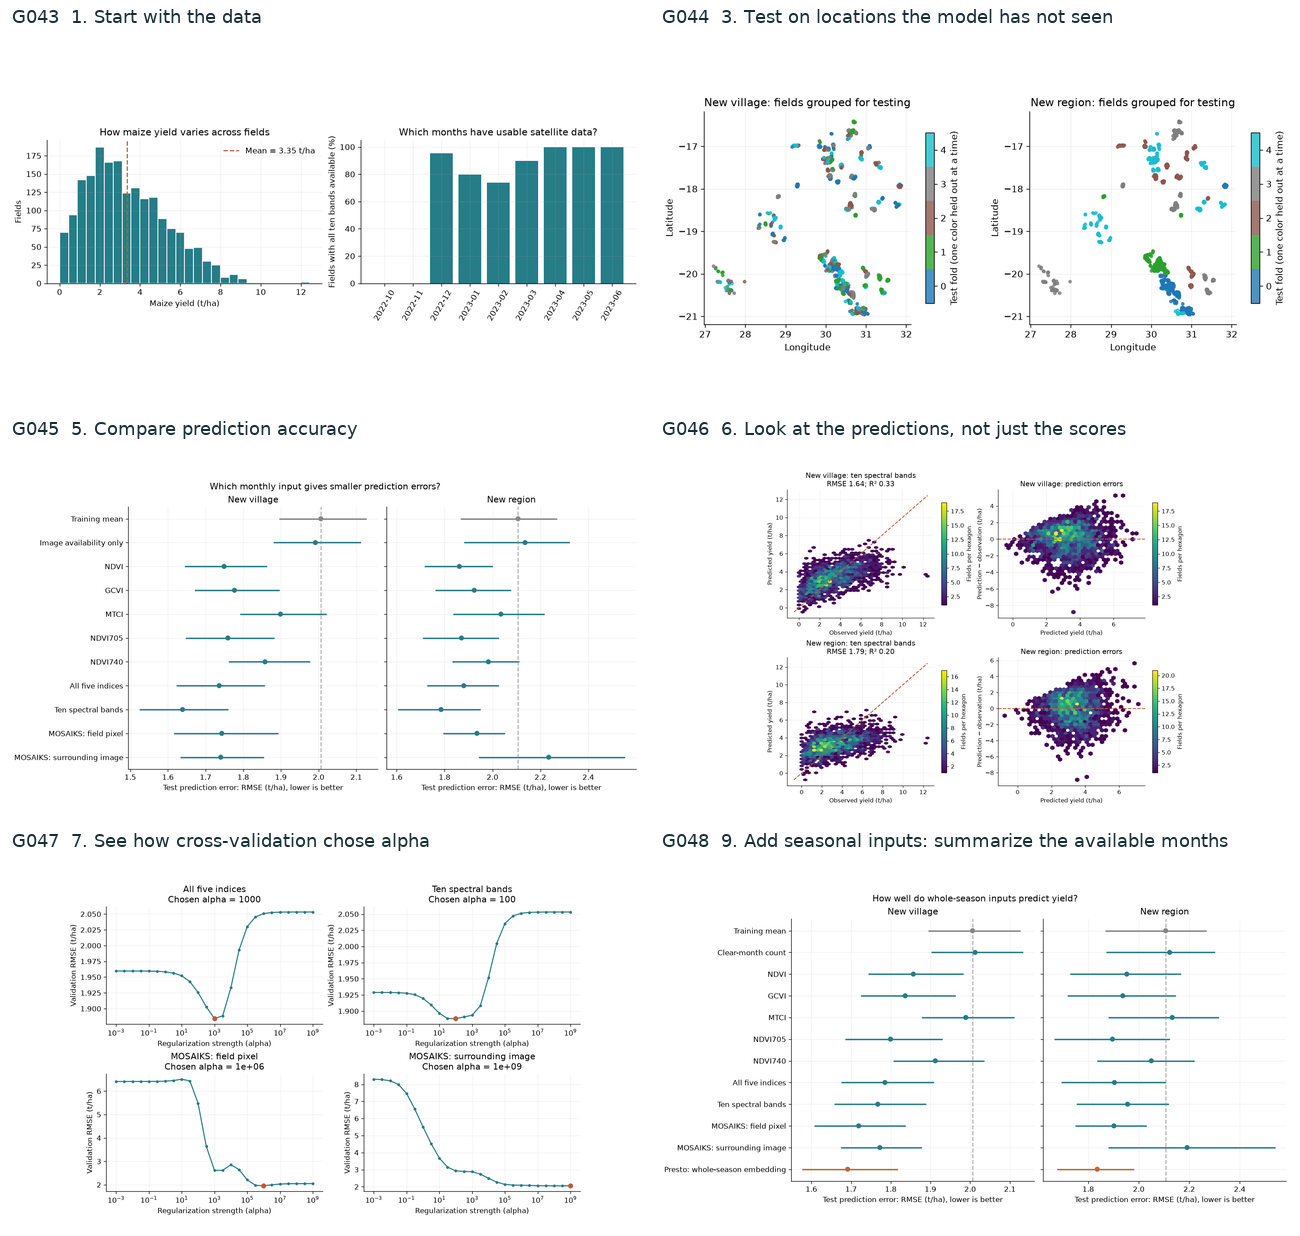

- **G043** [baselines.ipynb · cell 6, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G044** Each dot locates a Lacuna 2023 field. Colors identify the five test folds. The left panel assigns nearby villages to folds, while the right panel holds together fields in the same provider region. [baselines.ipynb · cell 12, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G045** [baselines.ipynb · cell 21, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G046** [baselines.ipynb · cell 24, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G047** [baselines.ipynb · cell 27, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G048** [baselines.ipynb · cell 36, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

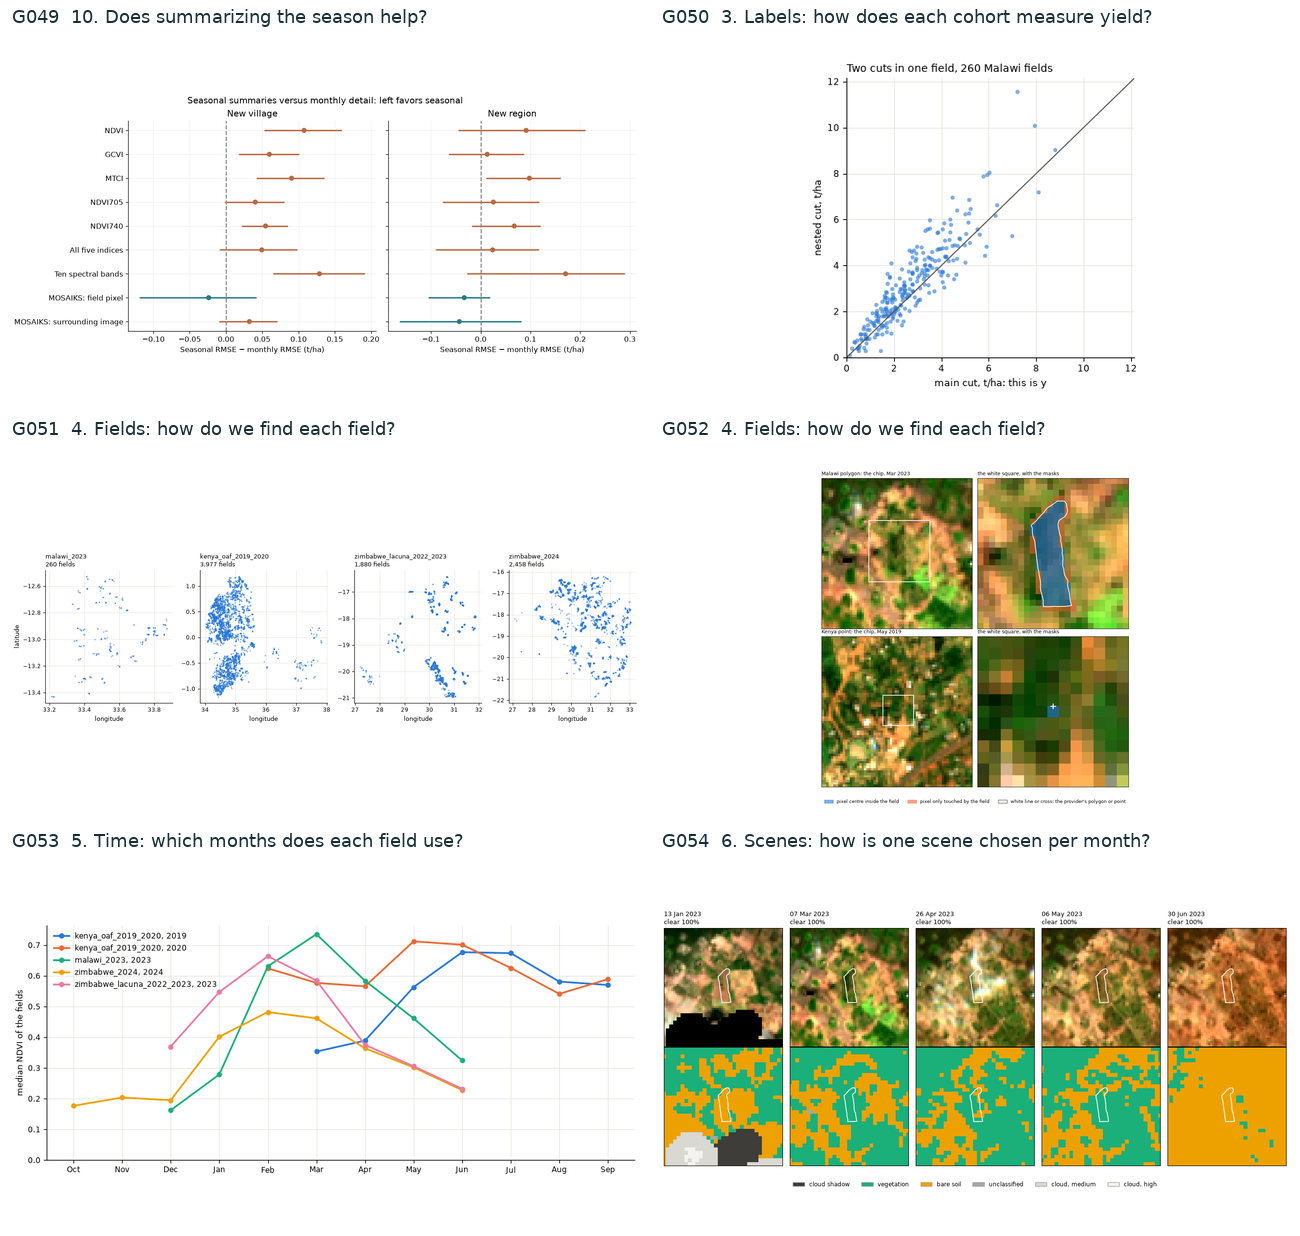

- **G049** [baselines.ipynb · cell 38, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G050** [data_guide.ipynb · cell 35, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G051** Blue dots locate the primary records in Malawi 2023, Kenya OAF, Lacuna and Zimbabwe 2024 using longitude and latitude. Each panel title gives its cohort and record count. [data_guide.ipynb · cell 37, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G052** The left column places a white zoom window on a Malawi polygon and a Kenya point. In the enlargements, blue marks pixels with centers inside the field, orange marks edge-only pixels, and the white outline or cross is the provider geometry. [data_guide.ipynb · cell 41, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G053** [data_guide.ipynb · cell 46, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G054** Five columns follow a Malawi field from January to June 2023. Visible-color images appear above their scene-classification masks. The white boundary marks the field, and the legend identifies cloud shadow, vegetation, bare soil and other classes. [data_guide.ipynb · cell 52, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

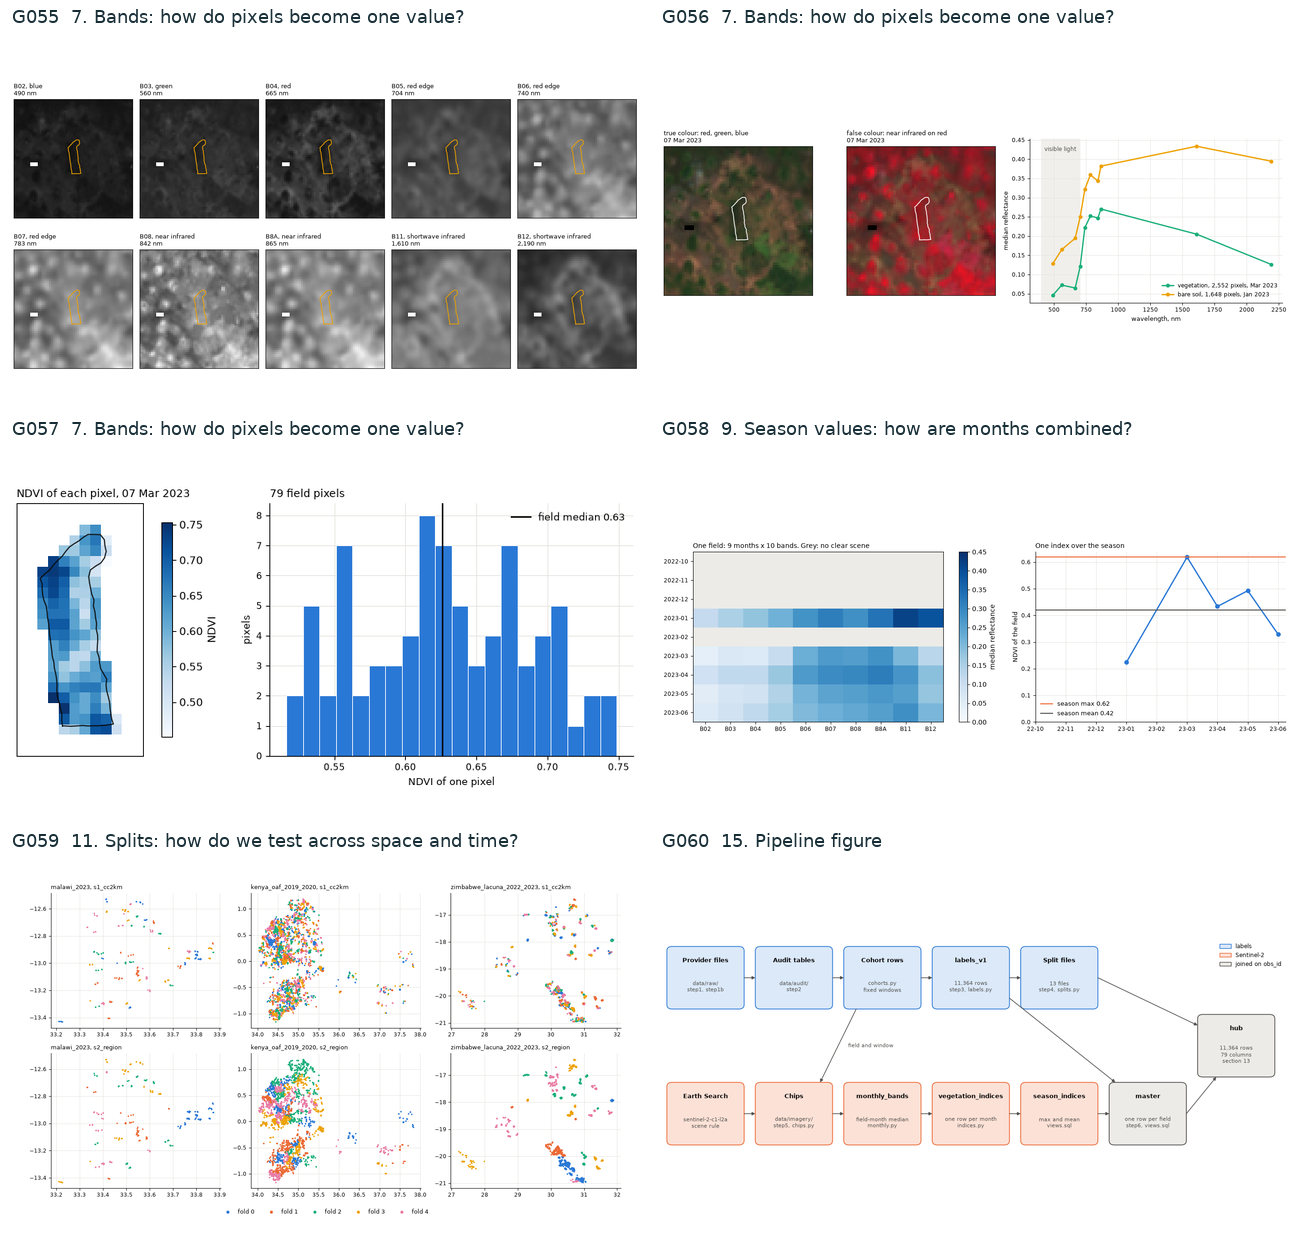

- **G055** Grayscale panels show ten spectral bands around the same Malawi field, outlined in orange. Lighter shades represent higher reflectance on a common scale. Wavelength labels distinguish the visible, red-edge and infrared bands. [data_guide.ipynb · cell 56, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G056** The first two panels show the same Malawi scene in visible color and near-infrared false color. Vegetation appears red in the second view. The wavelength plot at right compares vegetation, bare soil and the field median. [data_guide.ipynb · cell 58, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G057** Blue shades show NDVI across the outlined Malawi field on 7 March 2023. The adjacent histogram summarizes 79 interior pixels. The black line marks their median NDVI of 0.63. [data_guide.ipynb · cell 61, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G058** This field’s reflectance heatmap places months in rows and spectral bands in columns. Gray denotes months without clear imagery. The curve at right summarizes NDVI across the available months. [data_guide.ipynb · cell 70, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G059** For Malawi, Kenya and Lacuna, each point is a field and each color a test fold. The upper row groups locations using 2 km spatial connections. The lower row shows the regional split defined for each cohort. [data_guide.ipynb · cell 80, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G060** The diagram follows provider records and Sentinel-2 observations through label checks, monthly measurements, season summaries and the features used in modeling. Connecting lines identify the joins between the tables. [data_guide.ipynb · cell 94, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

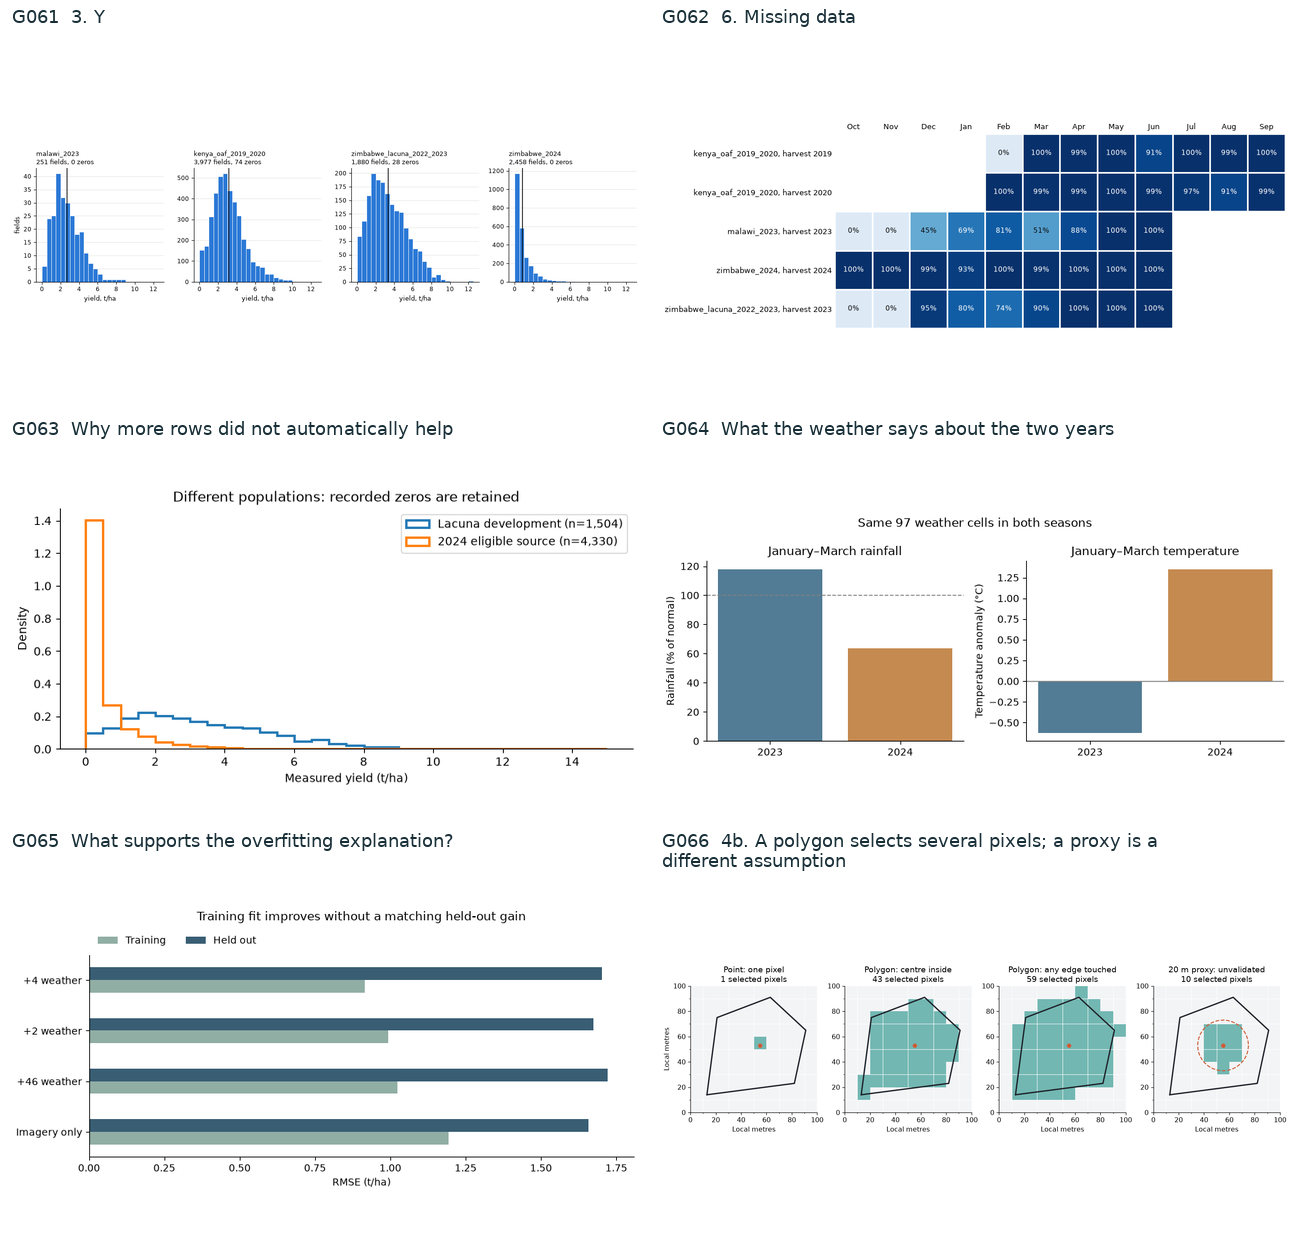

- **G061** [data_guide.ipynb · cell 102, output 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G062** Each row combines a cohort and harvest year. Percentages and blue shading give the share with nonmissing satellite measurements for each calendar month. Blank cells fall outside the displayed season for that cohort. [data_guide.ipynb · cell 109, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G063** [data_guide_2_zimbabwe.ipynb · cell 20, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)

- **G064** [data_guide_2_zimbabwe.ipynb · cell 38, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)

- **G065** [data_guide_2_zimbabwe.ipynb · cell 43, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)

- **G066** A synthetic field outline and point illustrate four pixel-selection rules. Teal cells show the pixels retained by a point, two polygon rules, and a 20 m circular proxy. Each panel reports the resulting count. [data_quality_review.ipynb · cell 17, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

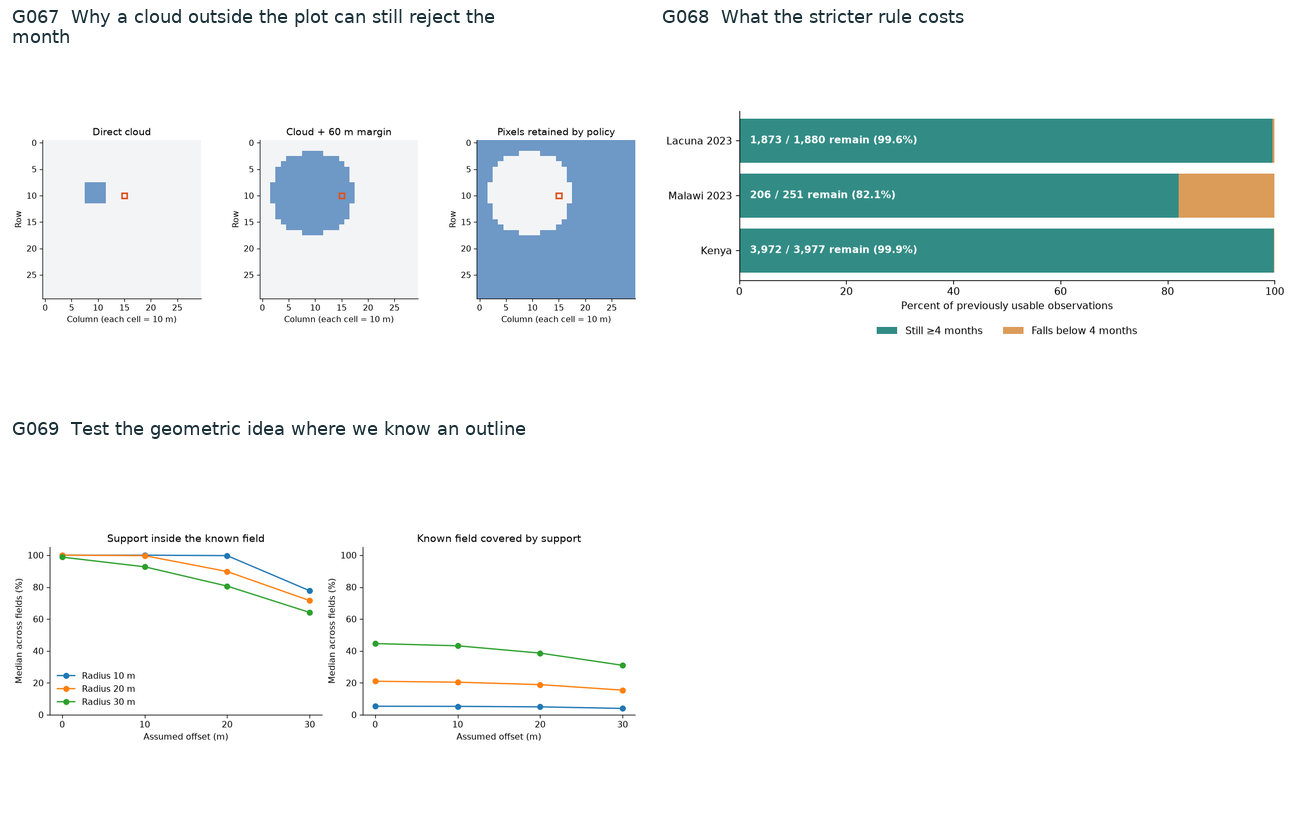

- **G067** On this synthetic 10 m grid, the left panel marks cloud pixels, the middle adds a 60 m margin, and the right shows retained pixels. The orange square locates an observation rejected because the margin reaches it. [data_quality_review.ipynb · cell 23, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

- **G068** [data_quality_review.ipynb · cell 25, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

- **G069** [data_quality_review.ipynb · cell 28, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

In [12]:
show_gallery(gallery, "Notebook figures")

### Archived notebook figures

26 unique previews · 26 figures referenced in this section.

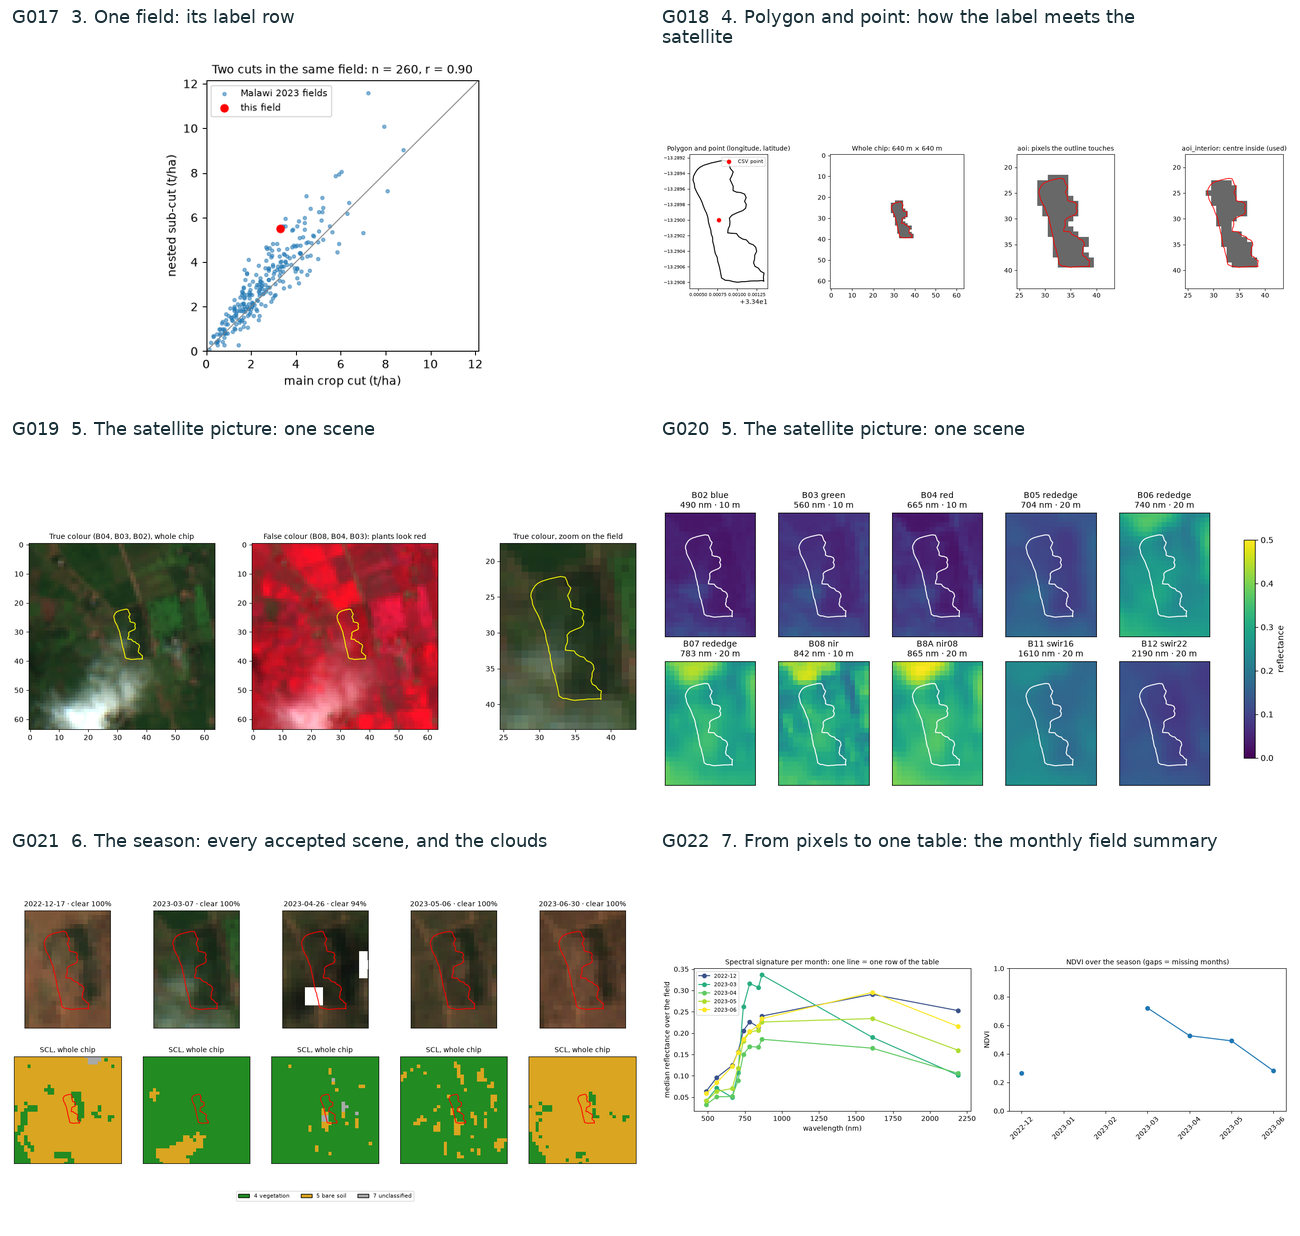

- **G017** [00_data_tour.ipynb · cell 8, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G018** The red point and black outline locate the same Malawi field. The following panels translate its outline to 10 m satellite pixels in a 640 m square. The last two compare all touched pixels with those whose centers lie inside. [00_data_tour.ipynb · cell 10, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G019** One Sentinel-2 acquisition shows a Malawi field outlined in yellow. The left and right views use visible light at two scales. The center assigns near-infrared reflectance to red, highlighting vegetation. [00_data_tour.ipynb · cell 13, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G020** All ten panels show the same outlined Malawi field on one date. Panel titles identify the Sentinel-2 band, wavelength and native resolution. The common color scale measures reflectance across the bands. [00_data_tour.ipynb · cell 13, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G021** Columns show five accepted scenes for the same Malawi field, outlined in red. The top row displays visible-color images. The lower row uses the legend to distinguish vegetation, bare soil and other scene classes across the surrounding chip. [00_data_tour.ipynb · cell 16, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G022** [00_data_tour.ipynb · cell 21, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

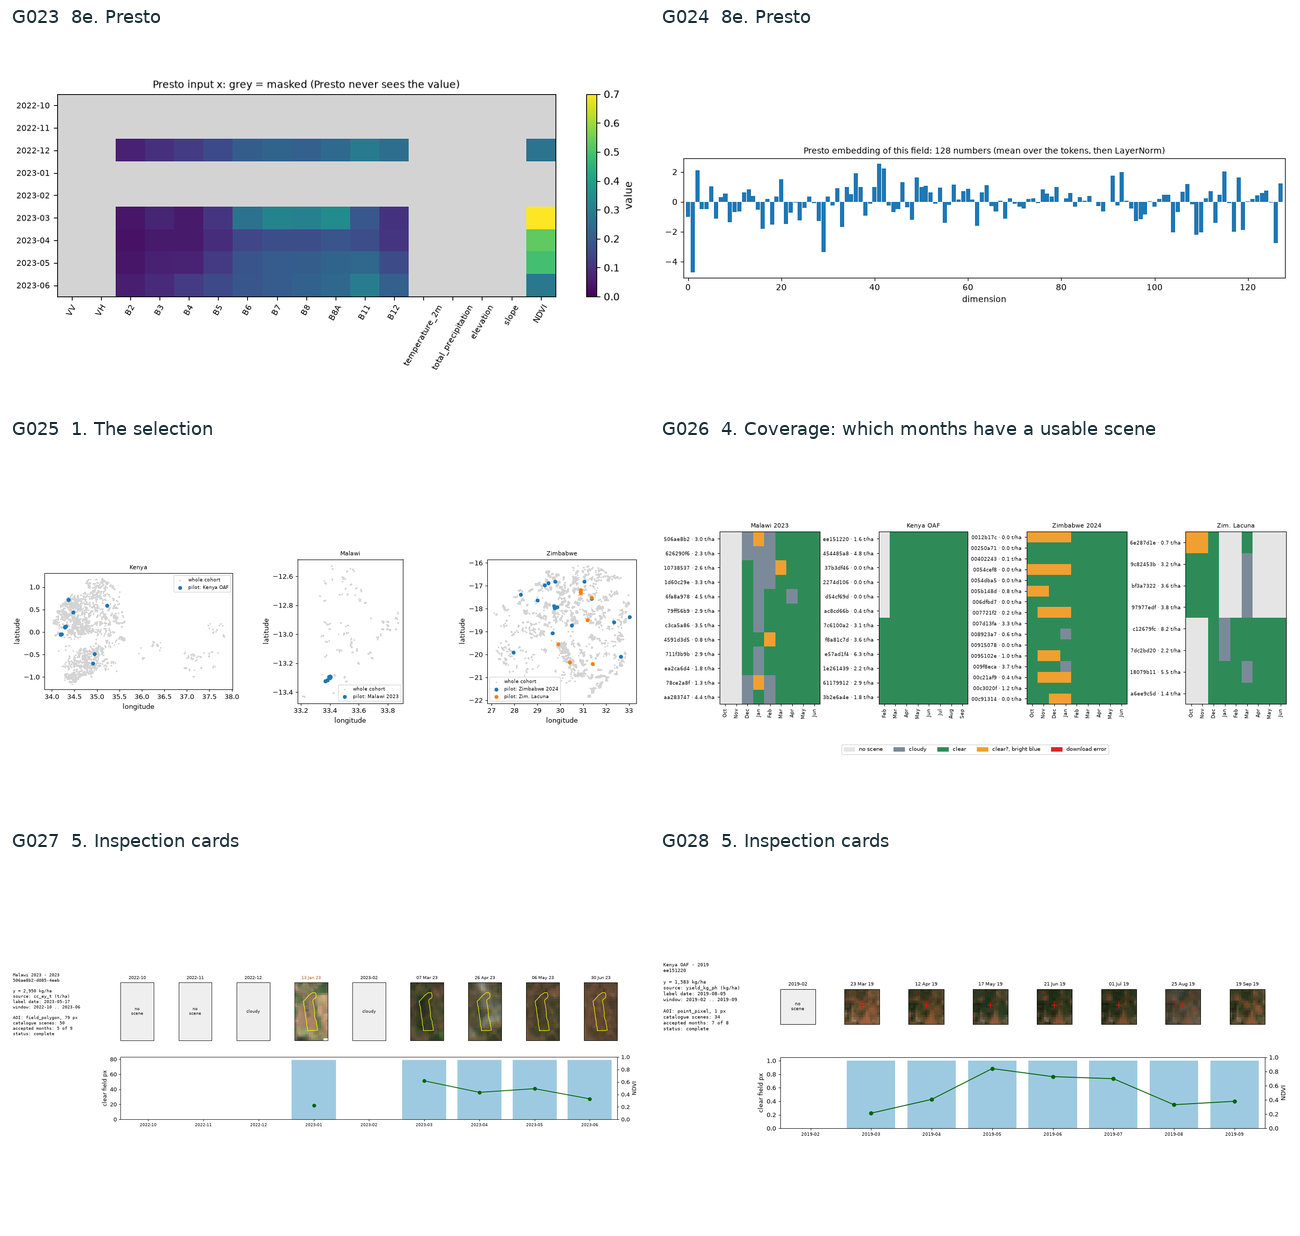

- **G023** Rows are months and columns are model inputs for the example Malawi field. Color shows the input value and gray marks entries masked before encoding. [00_data_tour.ipynb · cell 31, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G024** [00_data_tour.ipynb · cell 34, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G025** Dots place fields by longitude and latitude in Kenya, Malawi and Zimbabwe. Gray dots give the full cohorts. Larger colored dots mark fields chosen for the archived 48-field imagery pilot. [02_pilot48.ipynb · cell 5, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G026** Each row is a pilot field and each column is a month. Colors distinguish clear observations, cloudy attempts, absent scenes, bright-blue flags and download errors across four cohorts. [02_pilot48.ipynb · cell 11, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G027** The yellow outline follows a Malawi 2023 field through monthly Sentinel-2 scenes. Gray tiles identify unavailable or cloudy months. Blue bars count clear field pixels and the green line tracks NDVI. [02_pilot48.ipynb · cell 13, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G028** A red cross marks one Kenya OAF 2019 field location on the accepted monthly images. Bars count clear field pixels and the green line tracks NDVI from the available acquisitions. [02_pilot48.ipynb · cell 13, output 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

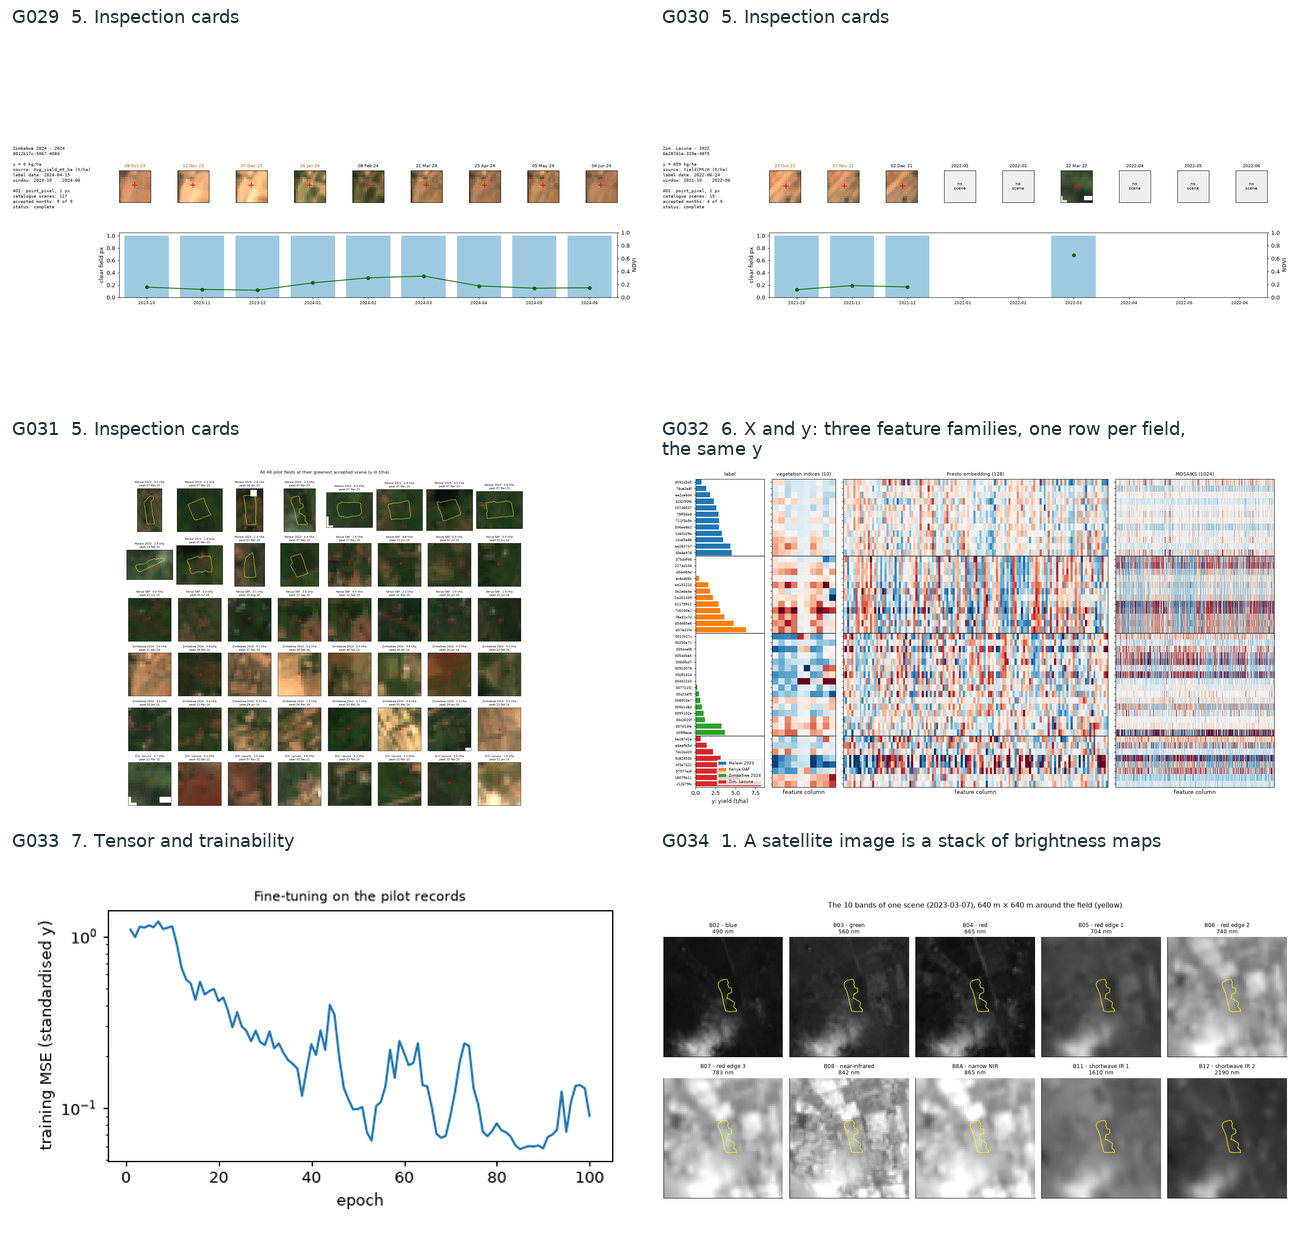

- **G029** A red cross locates one Zimbabwe 2024 record across nine monthly images. This example has a recorded zero yield. Blue bars count clear field pixels and the green line gives NDVI. [02_pilot48.ipynb · cell 13, output 4](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G030** A red cross locates one Lacuna 2022 observation on the available Sentinel-2 images. Gray tiles identify months without an accepted scene. The green NDVI line and clear-pixel bars use the available dates. [02_pilot48.ipynb · cell 13, output 5](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G031** Each tile shows a pilot field in its greenest accepted scene and gives its recorded yield in t/ha. Yellow boundaries identify polygon observations and red crosses mark point observations. [02_pilot48.ipynb · cell 14, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G032** Each row represents the same pilot field across three feature families. The bar at left gives measured yield. Blue and red cells show feature values below and above their column means after standardization. [02_pilot48.ipynb · cell 18, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G033** [02_pilot48.ipynb · cell 22, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G034** Ten panels show a 640 m square around the same Malawi field in the same satellite acquisition. The yellow line marks the field. Lighter grayscale values indicate stronger reflectance in the band named above each panel. [03_how_the_data_works.ipynb · cell 4, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

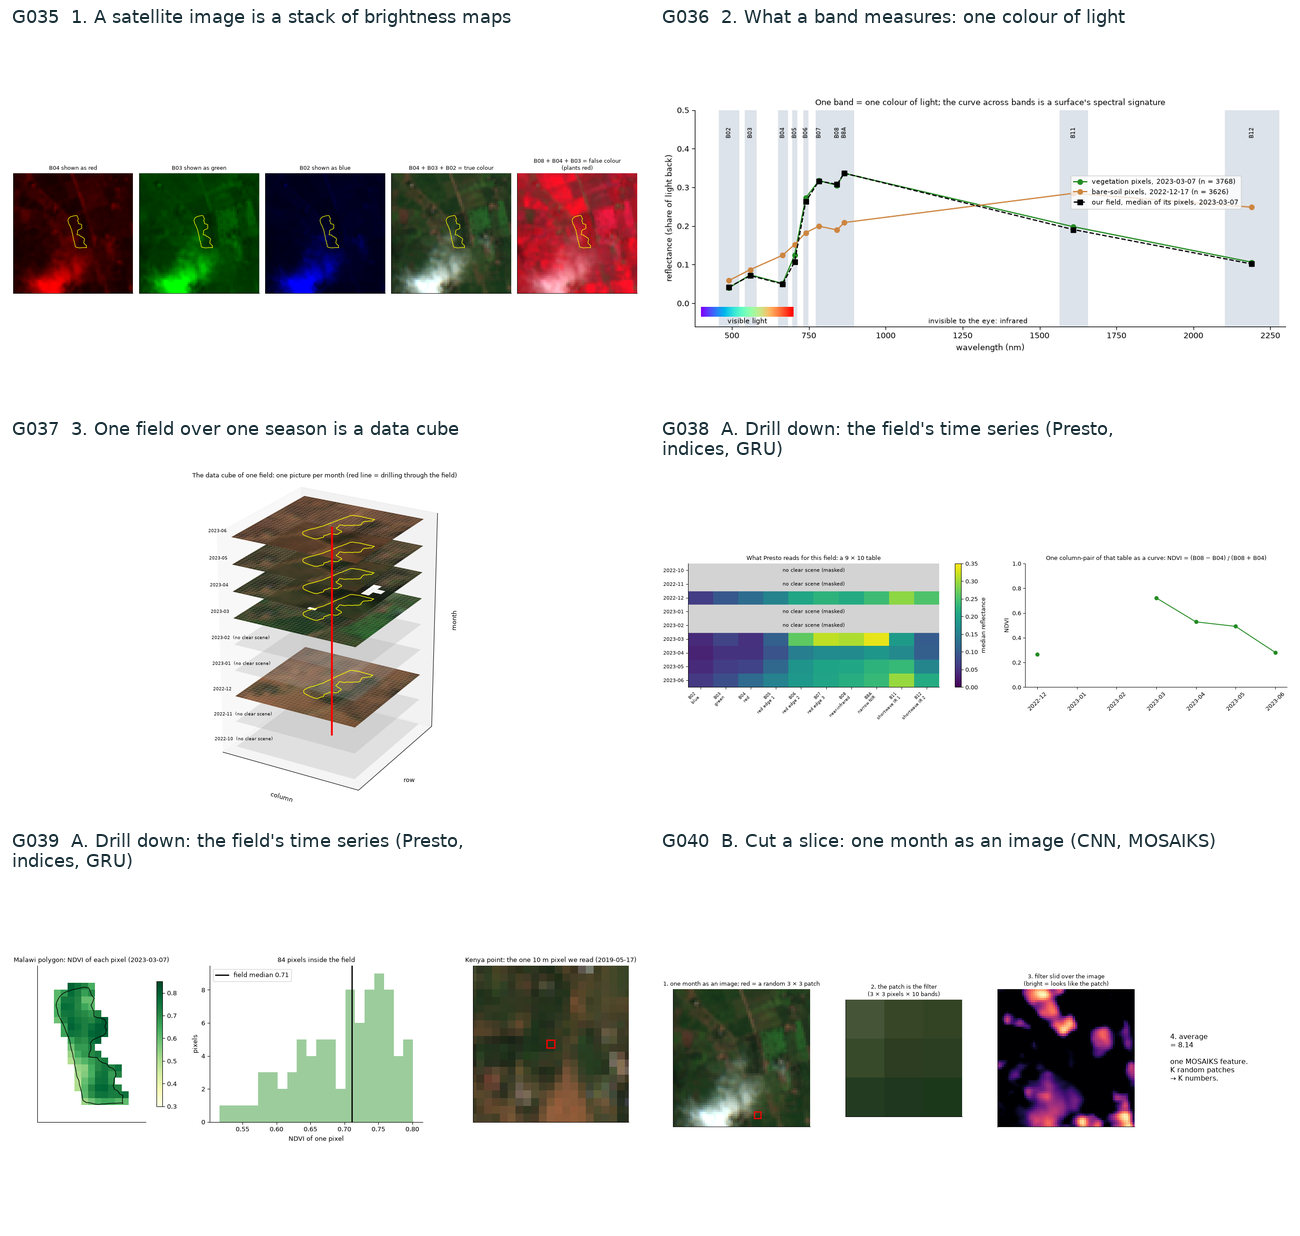

- **G035** The first three images display individual red, green and blue bands of the Malawi field. The last two combine them into visible color and a near-infrared composite, where vegetation appears red. Yellow outlines mark the same field. [03_how_the_data_works.ipynb · cell 6, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G036** [03_how_the_data_works.ipynb · cell 8, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G037** Each layer is a monthly satellite view of one Malawi field. Yellow traces its boundary. The red vertical line marks one pixel through time, and translucent gray layers identify months without a clear scene. [03_how_the_data_works.ipynb · cell 10, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G038** The left heatmap shows monthly median reflectance by band for one field, with gray rows marking gaps. At right, the red and near-infrared band values from that table are combined into an NDVI time series. [03_how_the_data_works.ipynb · cell 12, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G039** Green shades at left show pixel-level NDVI within a surveyed Malawi field. The center histogram gives the distribution for its interior pixels. At right a red square marks the single 10 m pixel used for a Kenya point observation. [03_how_the_data_works.ipynb · cell 14, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G040** In a Malawi satellite chip, the red square picks a 3 × 3 pixel filter. The response map lights up where other patches produce a large filter response. The mean response produces one illustrative MOSAIKS feature. [03_how_the_data_works.ipynb · cell 16, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

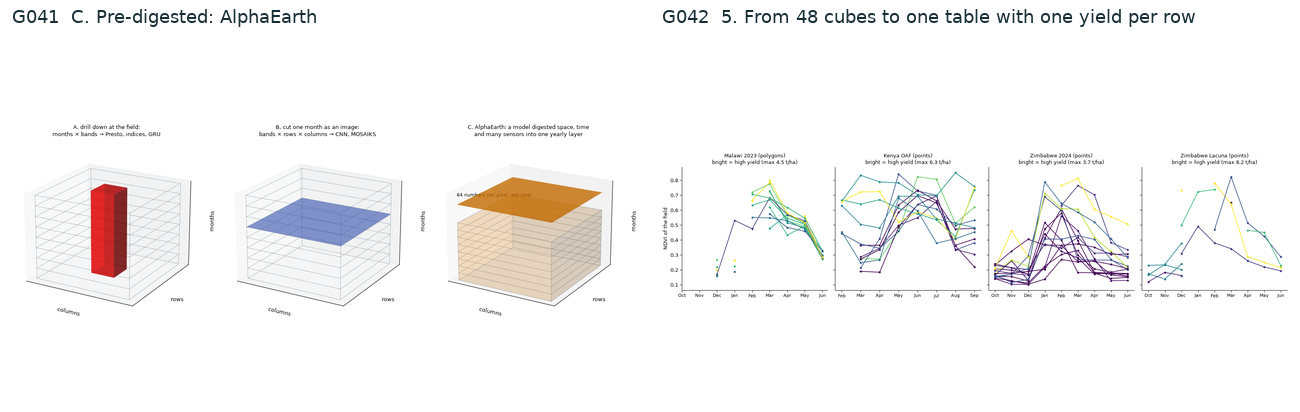

- **G041** These schematic cubes illustrate three ways to use an image sequence. The red column follows one location through time, the blue plane samples a whole image at one time, and the orange panel represents an annual embedding layer. [03_how_the_data_works.ipynb · cell 18, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G042** [03_how_the_data_works.ipynb · cell 20, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

In [13]:
show_gallery(gallery, "Archived notebook figures")

### Archived project diagrams

3 unique previews · 3 figures referenced in this section.

**G070 · From field observations to held-out yield estimates**

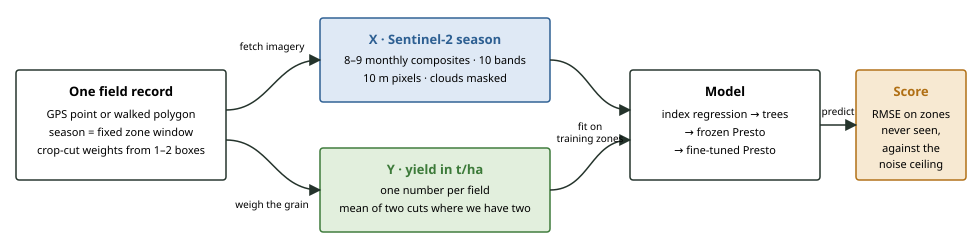

**G071 · From one field to satellite inputs and a yield label**

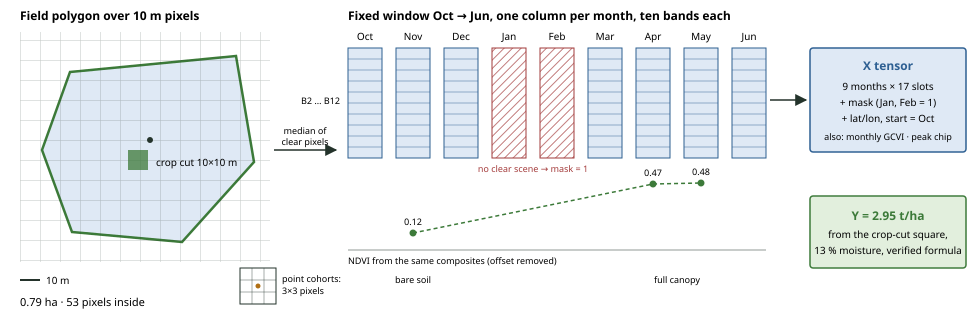

**G072 · Decision gates in the original experiment plan**

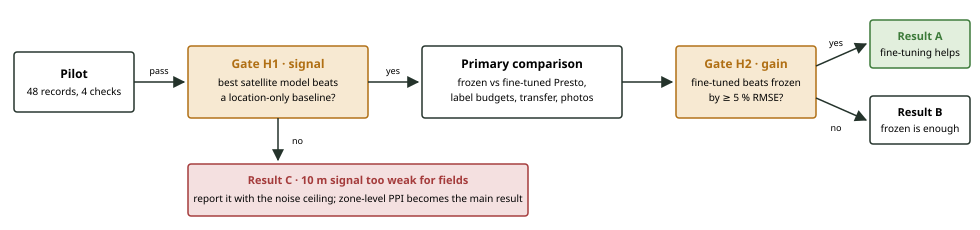

- **G070** This archived workflow traces ground observations and imagery through the prediction pipeline to held-out scoring. The arrows show dependencies among processing steps. [project_map_2026-10-25.html · diagram 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/docs/archive/project_map_2026-10-25.html)

- **G071** This archived sketch traces how the satellite observations for a field form a feature vector and how its crop-cut measurement supplies the yield target. [project_map_2026-10-25.html · diagram 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/docs/archive/project_map_2026-10-25.html)

- **G072** This archived decision diagram shows how pilot performance against a location baseline and the gain from fine-tuning determined the planned next experiment. [project_map_2026-10-25.html · diagram 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/docs/archive/project_map_2026-10-25.html)

In [14]:
show_gallery(gallery, "Archived project diagrams")

### Provider documentation figures

12 unique previews · 12 figures referenced in this section.

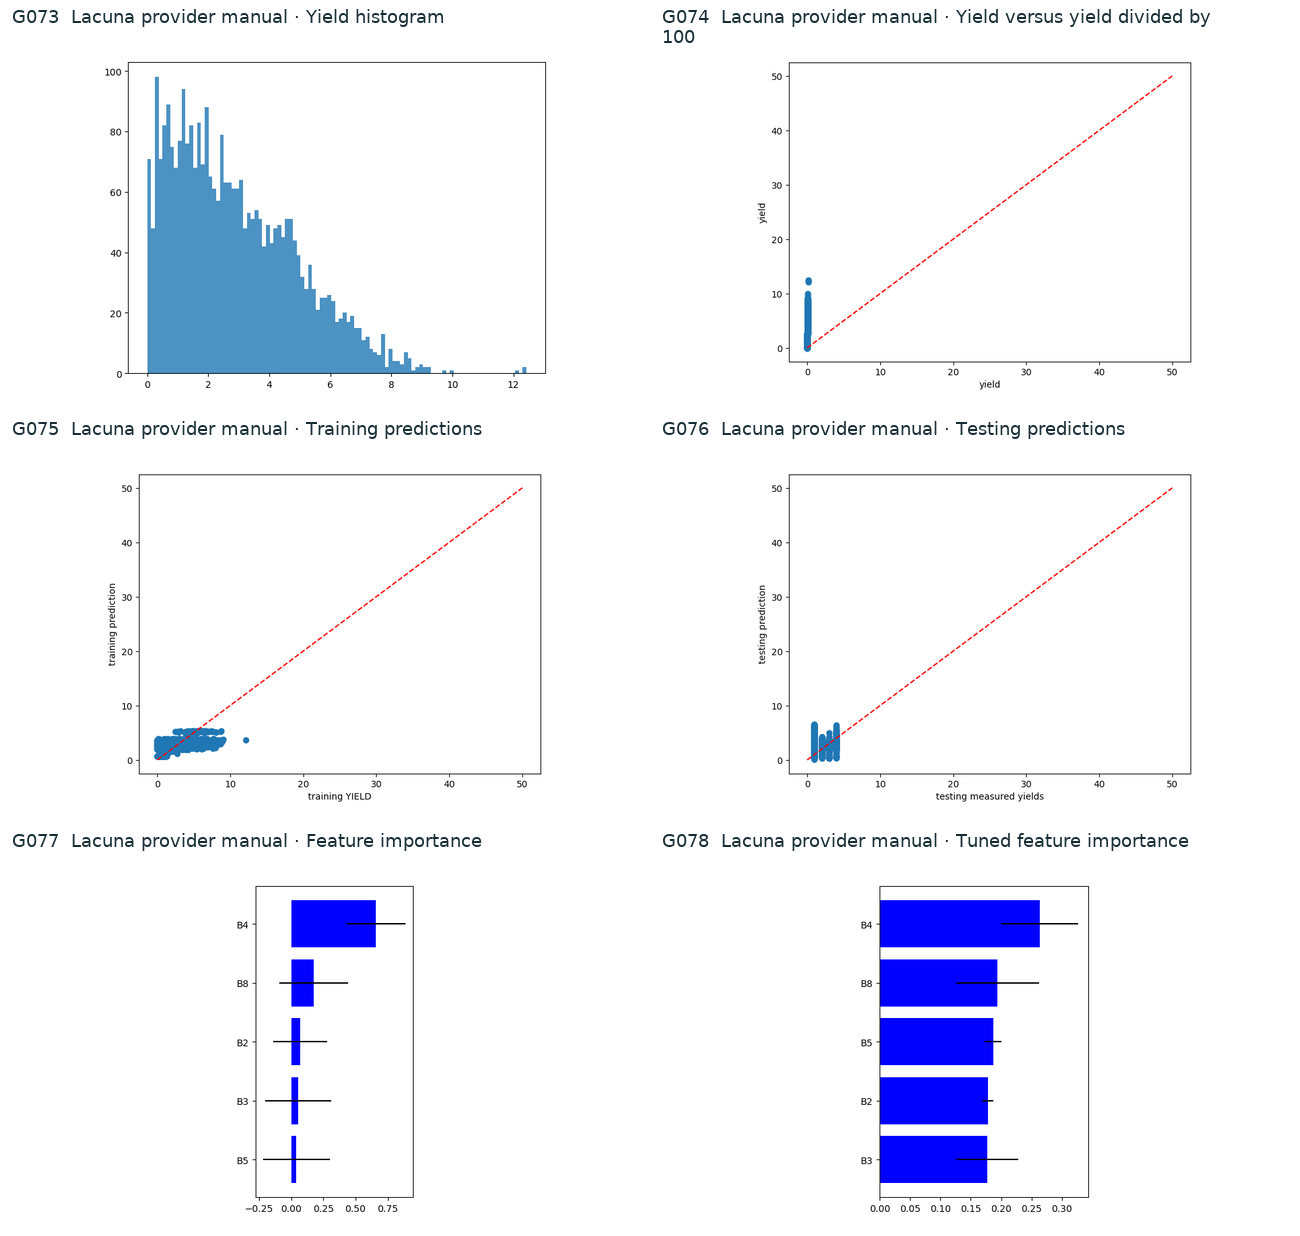

- **G073** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G074** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G075** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 6](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G076** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 4](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 7](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G077** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 5](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 8](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G078** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 6](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 9](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

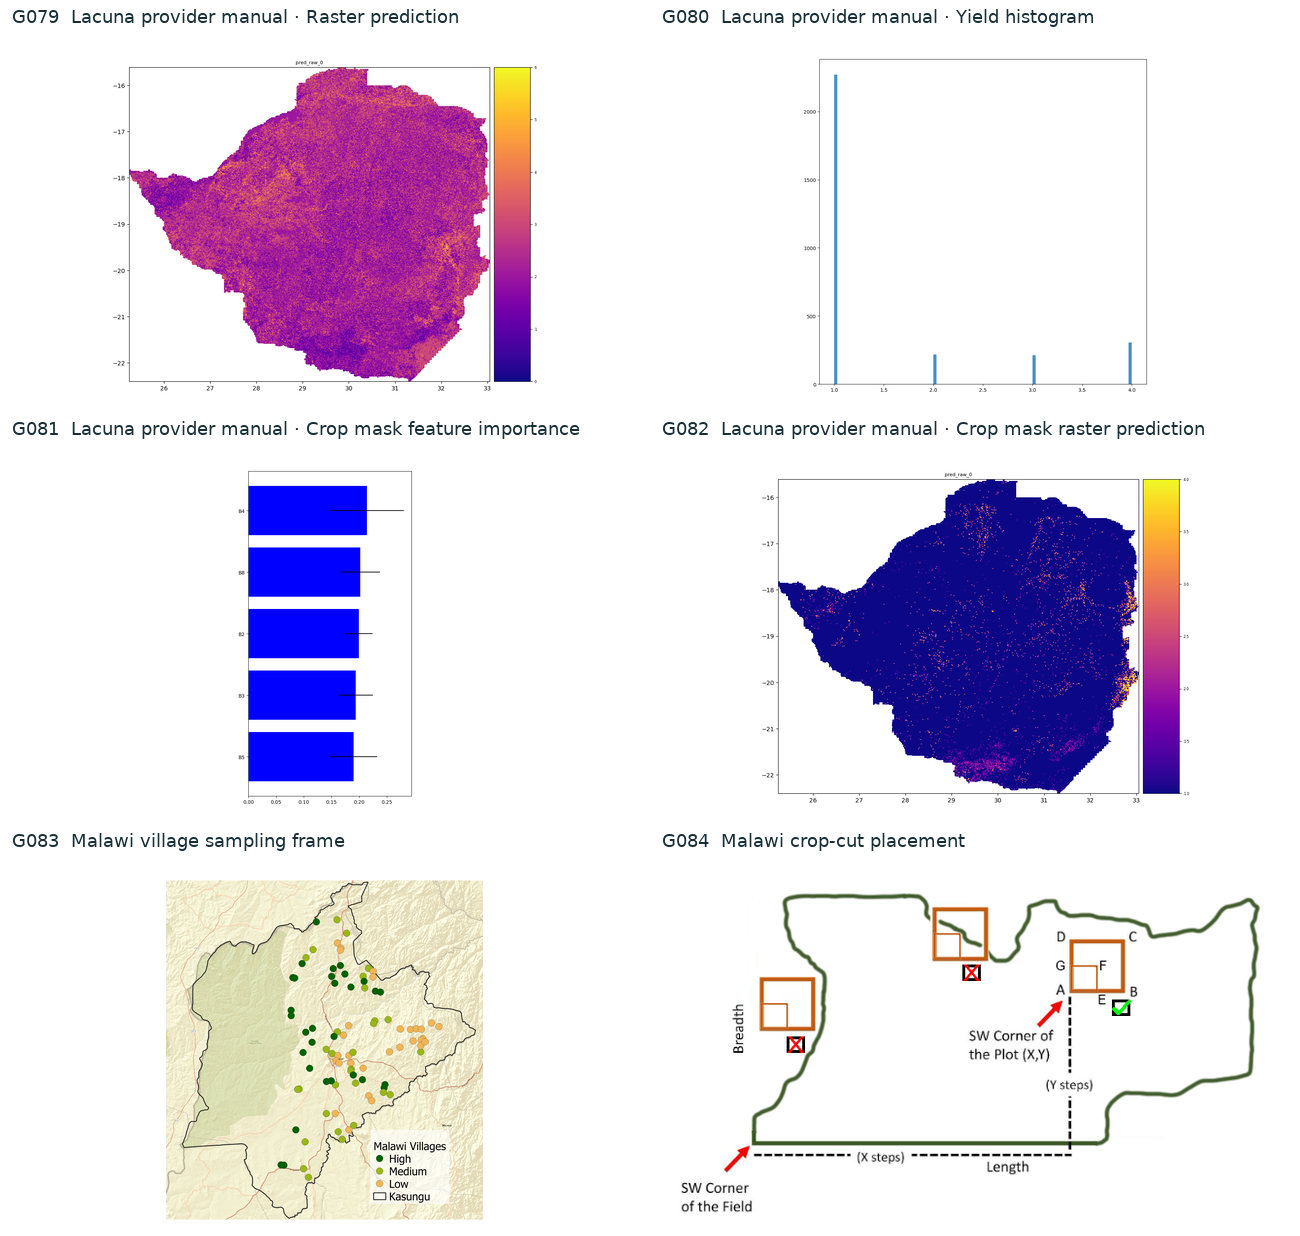

- **G079** The Lacuna provider’s random-forest example predicts yield across Zimbabwe from multispectral raster inputs. Dark purple through yellow denotes lower through higher model output on the published 0–6 scale. White lies outside the displayed raster footprint. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 7](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 11](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G080** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 8](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 12](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G081** [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 9](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 15](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G082** The Lacuna provider’s classifier assigns a crop class to each pixel in this Zimbabwe map. Purple, orange and yellow encode the published class codes 1–4. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 10](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 16](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G083** Dots locate villages in the Kasungu district sampling frame in Malawi. Dark green, light green and orange identify high, medium and low peak NDVI classes used for sample selection. The black outline marks the district. [nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx · word/media/image1.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/malawi/nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx)

- **G084** The Malawi fieldwork diagram locates the nested 5 × 5 m and 10 × 10 m crop cuts using distances from a field’s southwest corner. Crosses flag rejected placements and the check marks the accepted placement. [nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx · word/media/image2.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/malawi/nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx)

In [15]:
show_gallery(gallery, "Provider documentation figures")

### Reconstructed v2 report figures

4 unique previews · 4 figures referenced in this section.

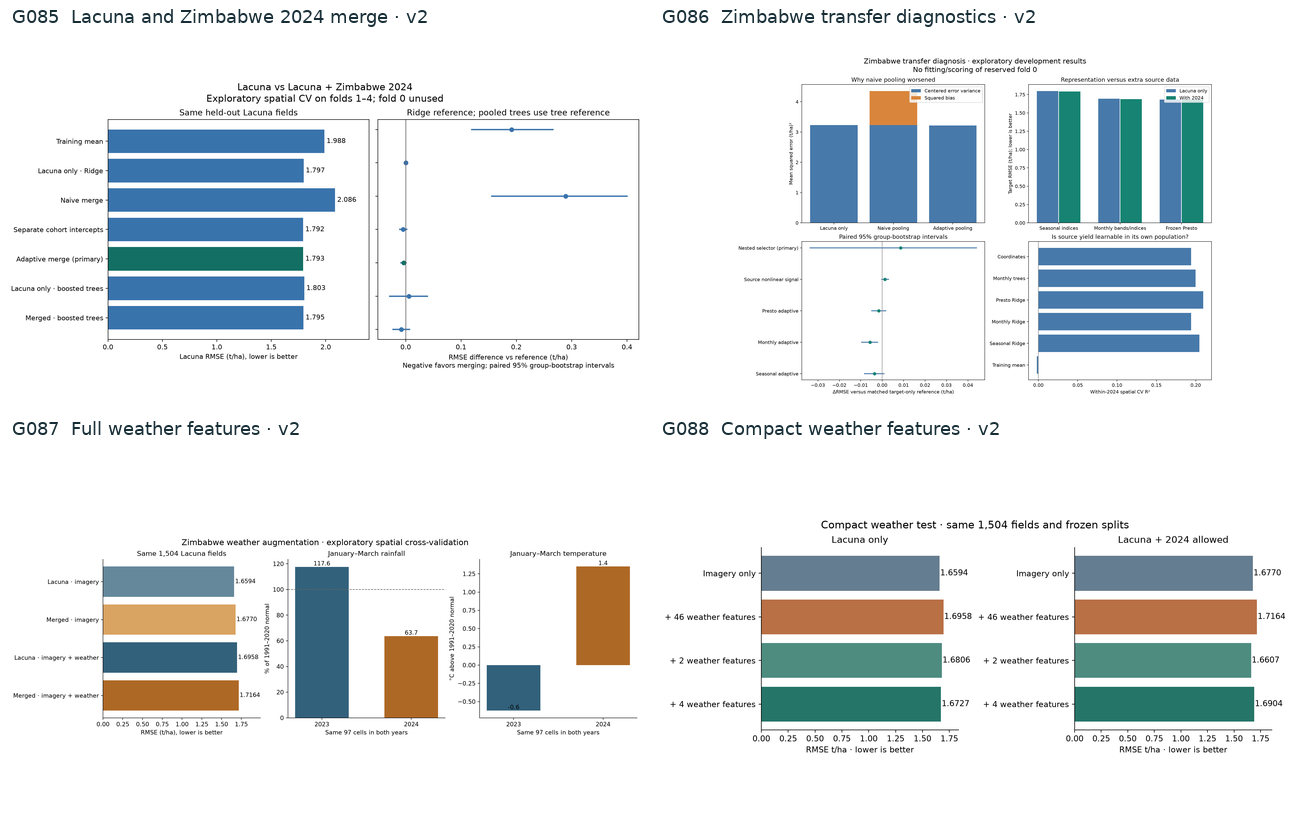

- **G085** [RESULTS.md · report link comparison.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/merge_v2/merge/RESULTS.md)

- **G086** [RESULTS.md · report link diagnosis.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/merge_v2/diagnosis/RESULTS.md)

- **G087** [RESULTS.md · report link weather_comparison.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/weather_v2/full/RESULTS.md)

- **G088** [RESULTS.md · report link compact_weather_comparison.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/weather_v2/compact/RESULTS.md)

In [16]:
show_gallery(gallery, "Reconstructed v2 report figures")

### Reconstructed Presto diagnostics

18 unique previews · 18 figures referenced in this section.

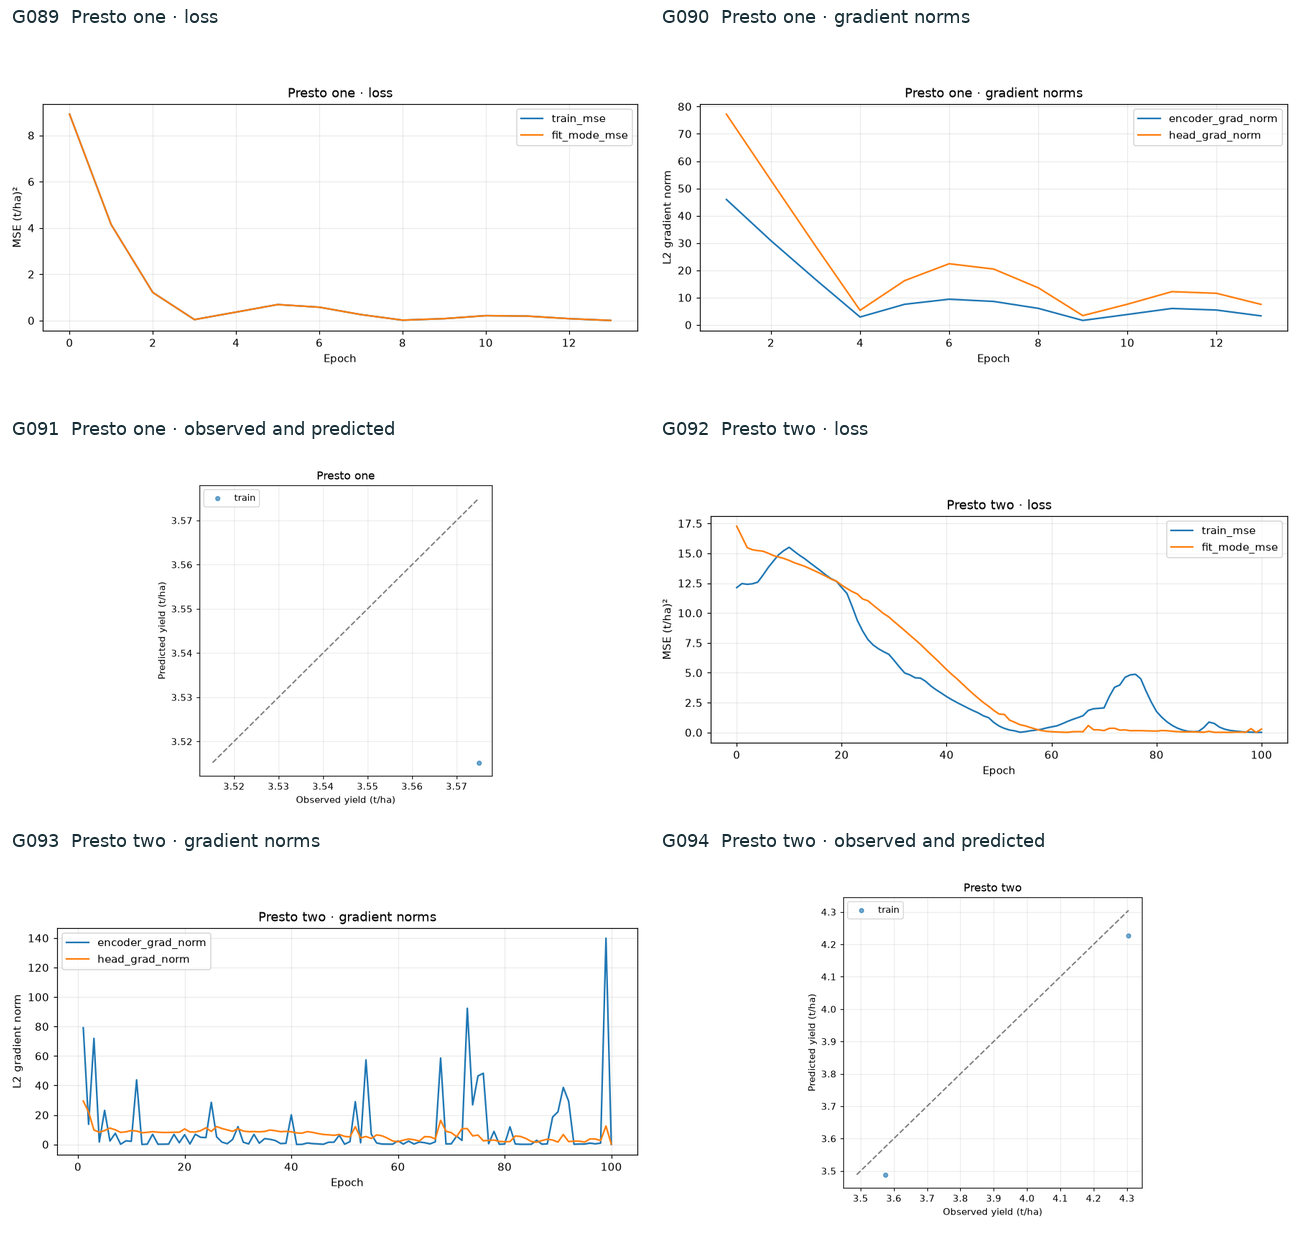

- **G089** [history.csv · one](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/one/history.csv)

- **G090** [history.csv · one](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/one/history.csv)

- **G091** [predictions.csv · one](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/one/predictions.csv)

- **G092** [history.csv · two](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/two/history.csv)

- **G093** [history.csv · two](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/two/history.csv)

- **G094** [predictions.csv · two](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/two/predictions.csv)

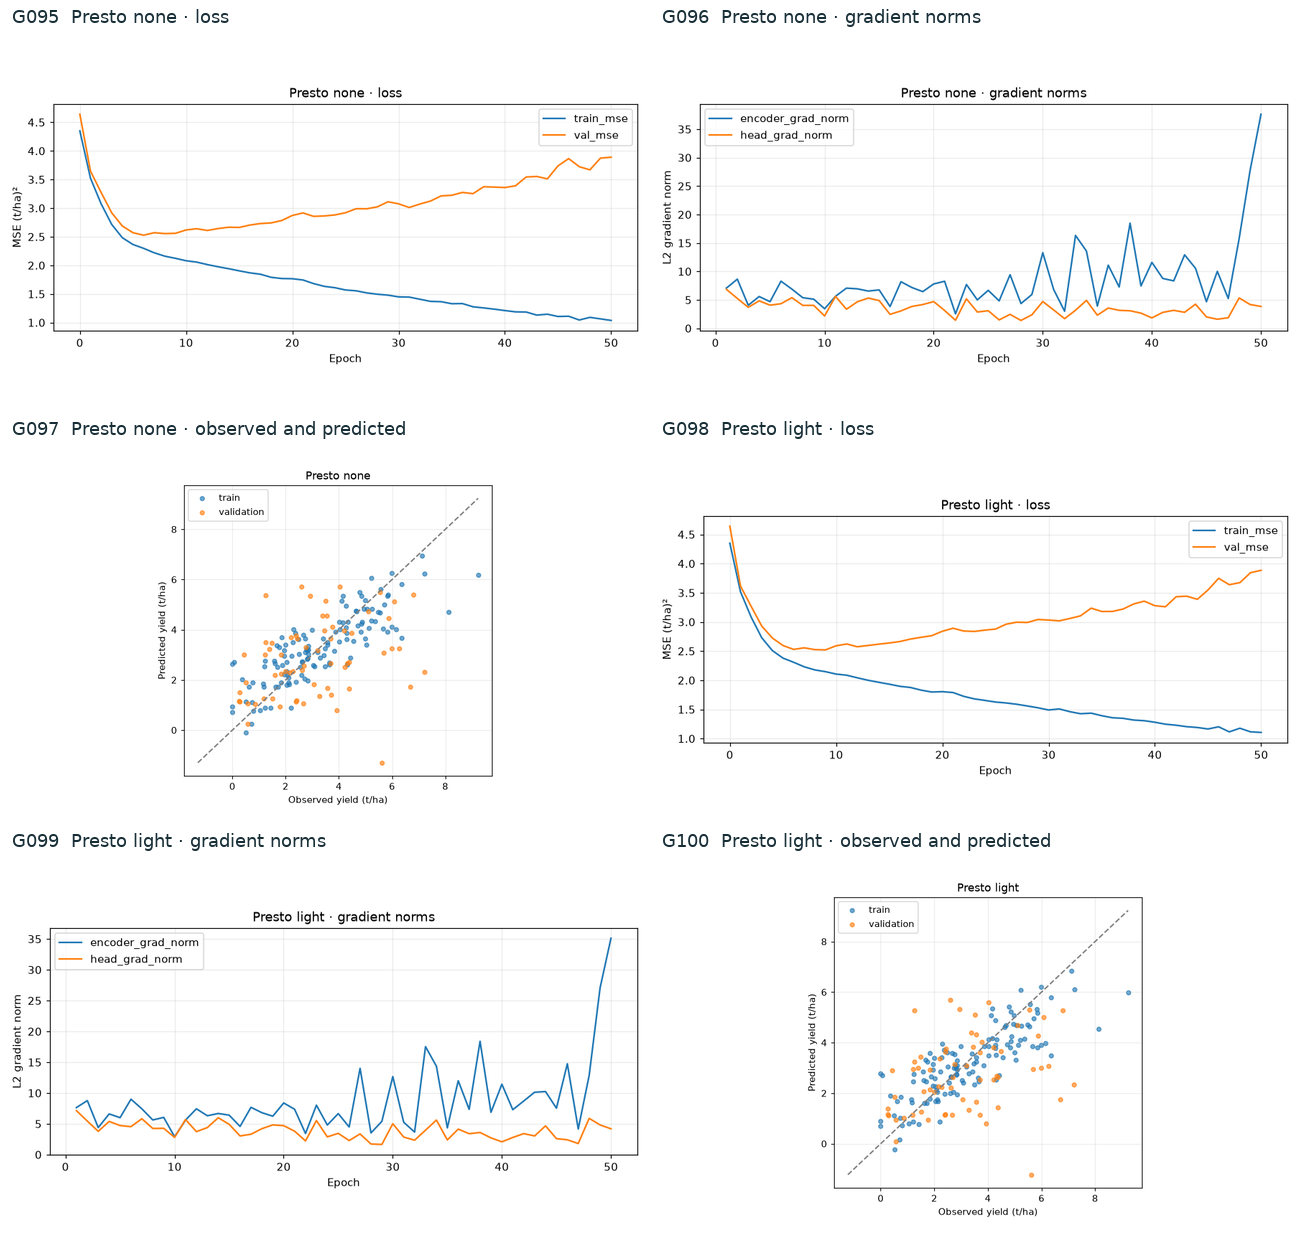

- **G095** [history.csv · none](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/none/history.csv)

- **G096** [history.csv · none](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/none/history.csv)

- **G097** [predictions.csv · none](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/none/predictions.csv)

- **G098** [history.csv · light](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/light/history.csv)

- **G099** [history.csv · light](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/light/history.csv)

- **G100** [predictions.csv · light](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/light/predictions.csv)

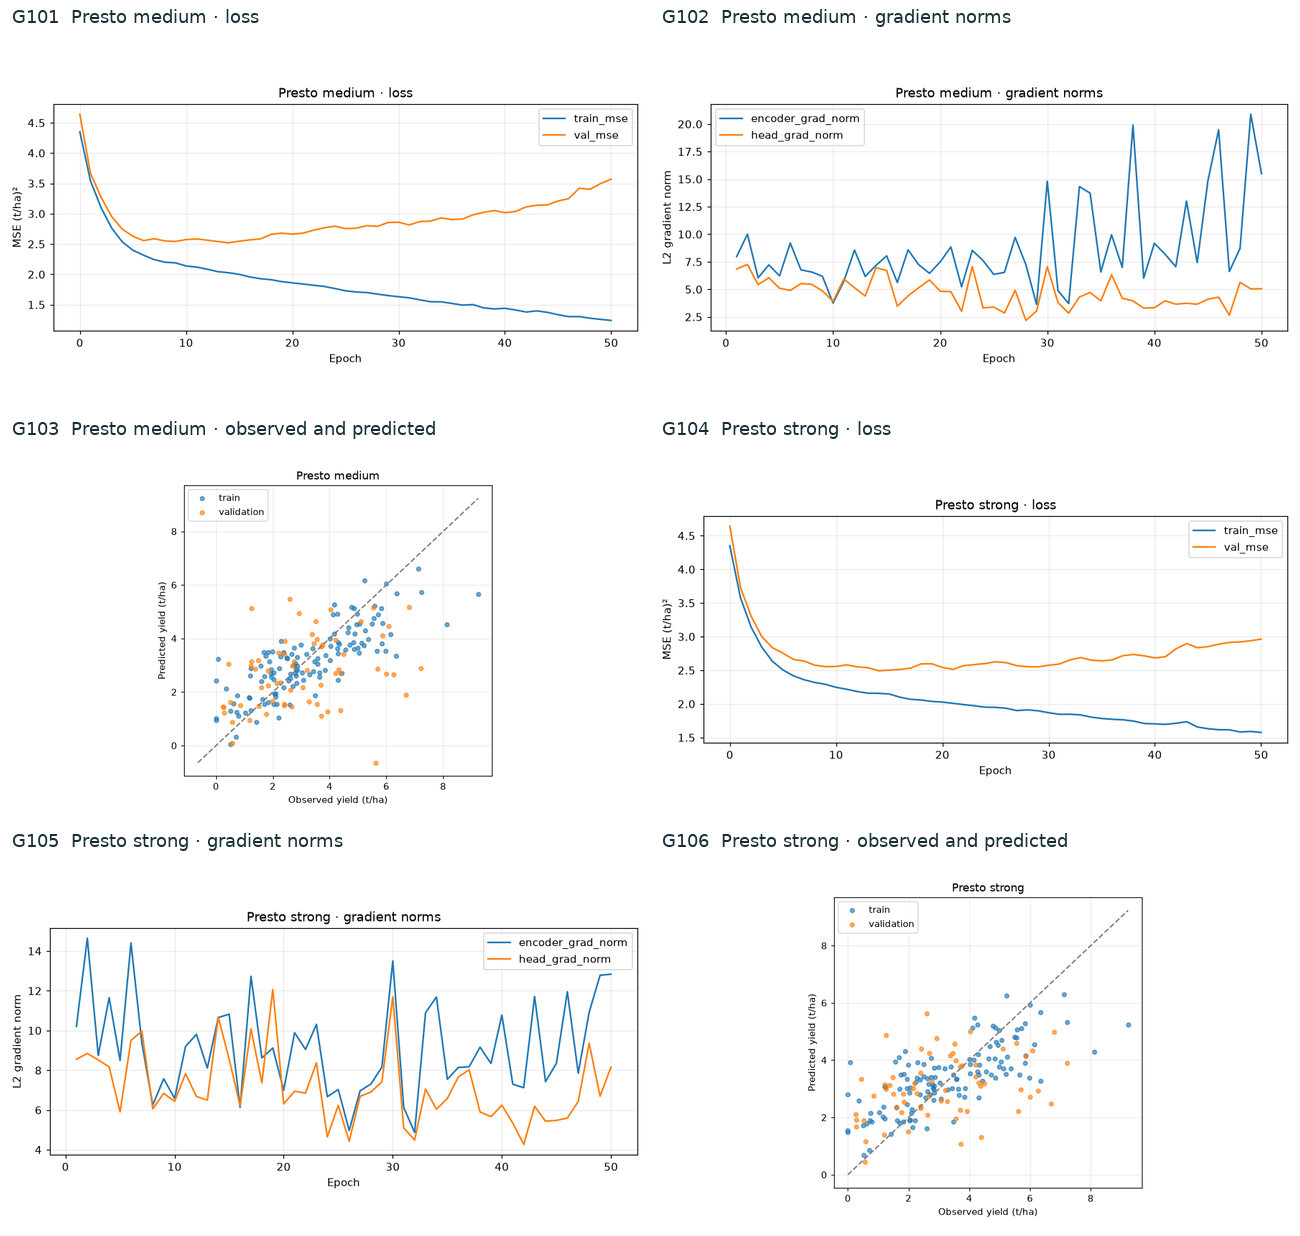

- **G101** [history.csv · medium](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/medium/history.csv)

- **G102** [history.csv · medium](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/medium/history.csv)

- **G103** [predictions.csv · medium](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/medium/predictions.csv)

- **G104** [history.csv · strong](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/strong/history.csv)

- **G105** [history.csv · strong](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/strong/history.csv)

- **G106** [predictions.csv · strong](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/strong/predictions.csv)

In [17]:
show_gallery(gallery, "Reconstructed Presto diagnostics")

In [18]:
# Enter an ID from the gallery to display its full-resolution image.
figure_id = ""
if figure_id:
    show_figure(gallery, figure_id.upper())